# Givers, Takers and the Shape of a City

This notebook builds a model of a city whose citizens play the Iterated Prisoner's Dilemma with the
people they meet. Some citizens are **givers**: they never cheat first. The others are **takers**:
they cheat. We change the share of givers from none to all, and measure three things: how much
wealth the city produces, how evenly that wealth is shared, and who ends up connected to whom.

We build the model in six steps, each adding one rule to the step before:

1. **S1:** everyone can meet everyone.
2. **S2:** citizens meet only their neighbours in a fixed network.
3. **S3:** relationships fade when they are not used, and break when they become too weak.
4. **S4:** citizens choose who to meet, based on distance, past meetings and reputation.
5. **S5:** citizens replace relationships they have lost.
6. **S6:** citizens stop meeting anyone who has cheated them.

*Explore One City*, after the parameter reference, runs a single city with settings you choose and
steps through it week by week. *Do the Results Depend on Our Settings?*, near the end, repeats the
hypothesis tests with each main setting changed.

The main results, each explained in the sections below:

- More givers always make a city richer.
- Without the S6 rule, a city where nobody ever cheats is almost as unequal as a mixed city. Most of
  the inequality comes from some citizens being met much more often than others, not from cheating.
- When citizens refuse to meet anyone who has cheated them, the overall level of inequality first
  changes little, but the poorest citizens become the takers. When the refusal is permanent, takers
  are cut off completely, and cities with many takers become poorer and more unequal.

## Background and Goal

**The phenomenon:** communities of similar size and resources can end up in very different places.
Some produce a lot of wealth and share it widely. Others produce less and concentrate it.
Cooperation is part of the explanation, but its benefit depends on the setting: across 957
estimates from 83 studies, the average effect of social capital on economic growth is close to
zero, with large positive and negative effects in different places [1]. What seems to matter
is who is connected to whom. In data on 21 billion Facebook friendships, the share of high-income
friends that low-income people have is one of the strongest predictors of upward mobility, while
how tight-knit a person's network is shows little association with it [2].

**Why an agent-based model:** nobody in a city chooses its level of prosperity, inequality or
segregation. These come out of many local interactions, each simple to describe. An agent-based
model simulates those interactions directly, instead of writing one equation for the whole city
[3].

**What is uncertain:** it is not clear whether cooperation also makes a society more equal.
Network-game models find inequality falling as cooperation rises [4], [5].
Laboratory experiments on clustered networks find more inequality, with rich and poor players
separating [6]. Making wealth visible increases early differences [7].

**Research question:**

> In simulated cities that differ in their mix of cooperative and exploitative agents, what patterns emerge in prosperity, in how that prosperity is distributed, and in who ends up connected to whom?

**Hypotheses:**

| # | Hypothesis | What would refute it |
|---|---|---|
| **H1** | **Prosperity threshold:** wealth per person rises with the share of givers, non-linearly, with a share below which cooperation cannot get established. | Wealth is a straight line in the giver share. |
| **H2** | **Prosperity and equality decouple:** inequality does not simply fall as givers increase; it flattens or rises in the richest cities, because cooperation relies on clusters [8], [9] and popular citizens attract more of the surplus. | Inequality falls steadily with the giver share on every network. |
| **H3** | **Emergent segregation:** givers end up tied to givers and takers are pushed to the edges, with no rule telling anyone to avoid anyone. | Class assortativity stays flat and takers keep giver-level ties. |
| **H4** | **The poverty trap is equal:** taker-dominated cities are poor but not unequal, so median wealth separates good cities from bad better than inequality does. | Taker-dominated cities are markedly unequal. |

H2 goes against what earlier network models found, so either result is informative.

## The Model

### Citizens and the game

Every citizen keeps one strategy for the whole run. Each meeting is one game of the Prisoner's
Dilemma, with the payoffs `(T, R, P, S) = (5, 3, 1, 0)` used in [3]:

| | Partner cooperates | Partner defects |
|---|---|---|
| **You cooperate** | 3 | 0 |
| **You defect** | 5 | 1 |

A pair of cooperators creates 6 units of wealth, a cooperator and a defector create 5, and two
defectors create 2. Wealth is created by games, not moved from one citizen to another, so a city's
total wealth reflects how its citizens have treated each other.

| Strategy | Behaviour | Class |
|---|---|---|
| **AllC** | Always cooperates. | Giver |
| **TFT** | Cooperates first, then copies the partner's last move. | Giver |
| **GTFT** | Like TFT, but forgives a defection with probability 0.1. | Giver |
| **TF2T** | Defects only after two defections in a row. | Giver |
| **Grudger** | Cooperates until the partner first defects, then always defects. | Giver |
| **Pavlov** | Repeats its last move if the partner cooperated, switches if not. | Giver |
| **AllD** | Always defects. | Taker |
| **Random** | Cooperates with probability 0.5. | Taker |
| **Joss** | Like TFT, but defects without being provoked with probability 0.1. Used only in the section on Joss. | Taker |

The **giver fraction** `f` is the share of citizens who are givers. Within each class the strategies
are split equally, so one number describes a city's population.

### Terms

- **Tie:** a relationship between two citizens who know each other. It has a **strength** that grows
  when they meet and fades when they do not. Having a tie does not mean the two meet every week.
- **Meeting:** one game between two citizens in one week. Each citizen starts one meeting a week and
  can also be chosen by others.
- **Tie capacity:** the most ties a citizen can hold, set to the number it starts with.
- **Popularity rating:** a score between 0.1 and 1 that reflects how cooperative and how well
  connected a citizen has been. It changes slowly. It is the only information others have about a
  citizen they have not met.
- **Taker-dominated / giver-dominated:** cities with `f <= 0.3` and `f >= 0.7`.

### One week

```
for each week:
    1. every citizen picks a partner      (distance x past meetings x reputation; in S6, never
                                           someone it has refused)
    2. each pair plays one game           (each strategy sees its own history with that partner)
    3. payoffs are added to wealth
    4. ties used this week get stronger
    5. unused ties fade with time since the last meeting
    6. ties below the threshold break
    7. citizens with spare capacity form new ties, mostly with friends of friends
    8. popularity ratings update
```

All citizens decide at the same time, using the state at the start of the week.

### The rules that decide behaviour

Three rules decide what citizens do, and S6 adds a fourth. Each rule is given as a formula, then in
words, with the values we use.

**Rule 1: who meets whom**

Each week every citizen picks one person to meet. Every possible partner `j` gets a score, and the
chance of picking them is their score divided by the total of all scores:

$$ s_{ij} = \underbrace{(w_{ij} + \varepsilon)^{\beta}}_{\text{past meetings}} \times \underbrace{R_j^{\gamma}}_{\text{reputation}} \times \underbrace{d_{ij}^{-\lambda}}_{\text{distance}} $$

- **Past meetings**, $w_{ij}$: the strength of the tie between `i` and `j`. Someone you meet often
  scores higher. A small amount, $\varepsilon = 0.1$, is added so that a person you have never met
  can still be picked. Without it, no new relationship could start.
- **Reputation**, $R_j$: `j`'s popularity rating, between 0.1 and 1 (rule 3).
- **Distance**, $d_{ij}$: how many steps through the network separate `i` and `j`. A neighbour is 1
  step away and scores 1; a friend of a friend is 2 steps away and scores 0.5. Nobody more than 3
  steps away is considered. In real social networks, the share of ties falls roughly as 1 over
  geographic distance [10]; we use the same shape for steps through the network.
- The exponents $\beta$, $\gamma$ and $\lambda$ set how much each part counts. All are 1 here.
  Setting one to 0 removes that part, which is how the steps of the model are built.
- **Example:** a well-rated neighbour you meet often ($w = 5$, $R = 0.9$, $d = 1$) scores
  $5.1 \times 0.9 \times 1 = 4.6$. A poorly rated stranger two steps away ($w = 0$, $R = 0.2$,
  $d = 2$) scores $0.1 \times 0.2 \times 0.5 = 0.01$. The neighbour is about 450 times more likely
  to be chosen.
- A citizen can be chosen by several others in one week. The number of meetings a citizen can
  **receive** is capped at $c_{max} = 4$ a week. Without a cap, the most popular citizen could
  receive any number of meetings.

**Rule 2: relationships strengthen, fade and break**

- Every meeting adds $\delta = 1$ to the strength of that tie.
- Between meetings, strength fades as $w \times e^{-\alpha \Delta t}$, with $\alpha = 0.05$ per
  week. A tie fades because it is not used, not because of anything that happened in the last game
  [11].
- A tie whose strength falls below $\theta = 0.1$ breaks. A tie of strength 1 takes
  $\ln(10) / 0.05 \approx 46$ weeks without a meeting to break.
- Each tie is judged on its own strength. If ties were instead compared with possible new partners,
  a stranger (strength near 0) could never replace someone already known, and the network would
  stop changing.

**Rule 3: popularity rating**

Each citizen has one rating, built from two things other citizens could notice:

- **How cooperative they have been recently**, $\kappa_j$: a slowly updated average of the share of
  their moves that were cooperative.
- **How connected they are**, $s_j$: the total strength of their ties, divided by the largest total
  in the city.

$$ R_j = R_{min} + (R_{max} - R_{min}) \times \kappa_j \times s_j = 0.1 + 0.9 \times \kappa_j \times s_j $$

The two are multiplied, so a citizen needs both to rate well: a cooperative citizen with few ties
and a well-connected defector both rate poorly. The lowest possible rating is 0.1, so every citizen
can still be chosen, though rarely.

No rule tells anyone to avoid takers. If takers end up with fewer partners, it is because defecting
lowers their rating, a lower rating means being chosen less, and a tie nobody uses fades and breaks.

**Rule 4 (S6 only): refusal**

- Once either citizen in a pair has defected on the other, the pair stops meeting. Neither can pick
  the other, and the tie between them breaks at once. Neither can be given a new tie to the other.
- The rule is the same for everyone and never mentions class or strategy. A taker is excluded only
  by the citizens it has cheated, one at a time. Two takers who defect on each other also stop
  meeting.
- By default the refusal is permanent. A setting `W` ends it `W` weeks after the pair's last game;
  the section *How Long a Refusal Lasts* varies `W`.
- Refusal replaces retaliation: a TFT citizen who has been cheated stops meeting the cheat instead
  of defecting back.

## Scenarios: What We Run and What We Expect

Each step adds one rule to the one before. When the new rule is switched off, a step reproduces
the step before exactly, with the same seed (this is tested in *Checks* below). So any difference
between two neighbouring steps comes from the rule that was added.

| ID | Network | Who you can meet | Ties | New ties | What it represents |
|:--:|---|---|---|:--:|---|
| **S1** | everyone tied to everyone | anyone, with equal chance | do not change | n/a | Everyone is equally likely to meet everyone |
| **S2** | random (Erdős–Rényi) | your neighbours, with equal chance | do not change | No | A fixed network of neighbours |
| **S3** | random (Erdős–Rényi) | your neighbours, with equal chance | fade and break | No | Relationships fade when unused |
| **S4** | random (Erdős–Rényi) | anyone within 3 steps, by distance x past meetings x reputation | fade and break | No | Citizens choose who to meet |
| **S5** | random (Erdős–Rényi) | as S4 | fade and break | Yes | Lost relationships are replaced |
| **S5b** | scale-free (Barabási–Albert) | as S4 | fade and break | Yes | As S5, on a network where a few citizens start with many ties |
| **S6** | random (Erdős–Rényi) | as S4, except anyone who has cheated you | as S5, and a tie breaks when a pair stops meeting | Yes | Citizens refuse anyone who has cheated them |

**What we expect, and why:**

- **S1:** takers do well, because they meet a new partner most weeks, so a partner who would punish
  them rarely meets them again. Inequality should be low, because nobody has an advantage of
  position.
- **S2:** citizens meet the same neighbours again and again, so givers that retaliate (TFT,
  Grudger) can punish takers [8]. We expect takers to gain less from cheating, and
  inequality to rise, because a citizen's results now depend on which neighbours it has.
- **S3:** a tie used every few weeks never fades enough to break, so we expect S3 to look like S2.
- **S4:** cooperative citizens earn higher ratings, are chosen more and play more games, so we
  expect givers to pull ahead, inequality to rise, and takers to lose ties.
- **S5:** replacing broken ties should keep the network in one piece without changing who does well,
  because new ties are chosen by the same rule.
- **S5b:** citizens who start with many ties should be chosen more, so we expect the highest
  inequality.
- **S6:** givers can now stop meeting a taker who cheated them, so we expect givers to keep more of
  their wealth and takers to lose partners. A taker that nobody meets creates no wealth, so the city
  as a whole could become poorer.

## Protocol and Assumptions

**Runs:**

1. `N = 100` citizens per city and `T = 500` rounds. One round is one week.
2. **5 seeds** per setting (`N_SEEDS` below), and giver fractions `f` of 0, 0.2, 0.4, 0.6, 0.8 and 1.
3. The same seeds are used in every scenario, so the same seed gives the same starting city in each.
4. Every random step draws from one seeded `numpy` generator passed through the model, so a run can
   be repeated exactly from its seed and settings.
5. Every city starts with zero wealth and every tie with the same strength.

**Measures** (taken at week 500 unless stated):

| Measure | What it means |
|---|---|
| **Wealth per person** | Mean wealth. Our measure of prosperity. |
| **Median wealth** | The wealth of the middle citizen. It falls below the mean when a few citizens hold much more than the rest. |
| **Gini coefficient** | Inequality of wealth, from 0 (everyone has the same) to 1 (one citizen has everything). |
| **Cooperation rate** | Share of all moves that were cooperative, averaged over the last 100 weeks. |
| **Taker payoff gap** | A taker's average payoff per game minus a giver's. Positive means cheating pays. |
| **Class assortativity** | Whether ties link citizens of the same class more than chance would: positive means givers are tied mostly to givers, negative means ties link givers and takers more than chance. |
| **Realised partners** | The number of different citizens each citizen played in the last 100 weeks. |
| **Games played, by class** | The number of games each giver and each taker has played. |
| **Gini of games played** | Inequality in the number of games played. |
| **Between-class share** | The share of inequality that lies between the average giver and the average taker, from the Theil index (0: classes equally well off on average; 1: all inequality is between the classes). |
| **Gini of surplus** | The Gini of wealth after subtracting the mutual-defection payoff `P = 1` from every game, so that being cheated costs wealth. |
| **Takers shut out** | Share of takers with no ties. |

**Assumptions:** strategies never change; citizens cannot refuse a game, except in S6; wealth is
never spent; and no citizen is born, dies, arrives or leaves.

## Parameter Reference

Values used in every run below. The model exposes each as a configuration key, and alternatives listed in the right-hand column can be selected without changing code.

| Symbol | Config key | Meaning | Value here | Alternatives available |
|---|---|---|---|---|
| `N` | `population.n_agents` | agents per city | 100 | any |
| `T` | `run.n_rounds` | rounds per run | 500 | any |
| `f` | `population.giver_fraction` | share of givers | 0 to 1, step 0.2 | any |
| `k` | `topology.mean_degree` | mean degree of the starting network | 6 | any |
| | `topology.name` | starting network | `erdos_renyi`, `barabasi_albert` | `watts_strogatz`, `complete` |
| `(T,R,P,S)` | `game.payoff` | payoff matrix | (5, 3, 1, 0) | any ordering |
| `rho` | `game.rho` | resource density, a payoff multiplier | 1.0 | any |
| `c` | `game.subsistence_cost` | wealth deducted per agent per round | 0.0 | any |
| `nu` | `game.noise` | chance an intended move is flipped | 0.0 | any |
| `B` | `encounter.initiated` | meetings each agent starts per round | 1 | any |
| `c_max` | `encounter.max_received` | cap on meetings received per round | 4 | any, or no cap |
| `d_max` | `encounter.d_max` | furthest candidate partner, in hops | 3 | any |
| `lambda` | `encounter.distance_exponent` | pull of proximity | 1.0 | any; rank-based form |
| `beta` | `encounter.weight_exponent` | pull of habit | 1.0 | any |
| `gamma` | `encounter.popularity_exponent` | pull of status | 1.0 | any |
| `eps` | `encounter.eps` | offset allowing contact without a tie | 0.1 | any |
| `alpha` | `ties.decay_rate` | tie decay per round | 0.05 | any |
| `theta` | `ties.severance_threshold` | ties below this break | 0.1 | any |
| `delta` | `ties.reinforcement` | weight added per meeting | 1.0 | any |
| `R_min`, `R_max` | `popularity.r_min`, `r_max` | rating bounds | 0.1, 1.0 | any |
| `eta` | `popularity.smoothing` | smoothing of the cooperation average | 0.1 | any |
| | `popularity.rule` | what the rating rewards | `behaviour_x_strength` | `weighted_sum` (`popularity.mix` from 1, cooperation only, to 0, tie strength only), `payoff_delivered` |
| | `ties.severance_rule` | how ties break | `absolute` | `none` |
| | `rewiring.rule` | how freed capacity is refilled | `local_refill` | `none` |
| | `encounter.refusal` | who an agent will not play | `none`; `experience` in S6 | `reputation` (anyone rated below a threshold) |
| `W` | `encounter.refusal_memory` | weeks a pair stays closed after a defection | forever | any number of weeks |
| | `encounter.refusal_threshold` | rating below which `reputation` refuses | 0.25 (unused here) | any |
| | `population.taker_composition` | mix within the taker class | AllD and Random, equally | any weights over AllD, Random, Joss |
| | `strategies.joss_defection` | Joss's chance of an unprovoked defection | 0.1 | any |
| `n_s` | seeds per point | repeats | 5 | any |

The decay rate, threshold, cap and offset were fixed by a calibration sweep that asked which settings keep a 50/50 city away from the extremes of total collapse and total cooperation.

In [1]:
# One BLAS thread per process: the sweep runs whole cities in parallel, so threads underneath
# them only contend. This must happen before numpy is imported.
import os
for _var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ.setdefault(_var, "1")

from pathlib import Path
import sys
import warnings

# Class-specific measures are undefined when a class is absent or has lost every tie (f = 0,
# f = 1, or takers shut out under refusal). Those cities report NaN, which is expected.
warnings.filterwarnings("ignore", category=RuntimeWarning)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "source").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from source import metrics
from source.presets import stage
from source.simulation import Simulation
from utilities import plotting as P
from utilities import runs as R
from utilities.checks import check, same_run, trace

P.use_style()
print(f"python {sys.version.split()[0]} | numpy {np.__version__} | networkx {nx.__version__} | pandas {pd.__version__}")

python 3.10.12 | numpy 2.2.6 | networkx 3.4.2 | pandas 2.3.3


## The Model in One Diagram

**Purpose and layout:** To show the order in which the rules act each week, and how the six scenarios
build on each other. Left: the six updates that make up one week in the full city (S5), with what S6
adds at steps 1 and 4. Right: the six scenarios, each adding one rule to the one before. The numbers in
the boxes are read from the model's default settings, so they match the runs below.

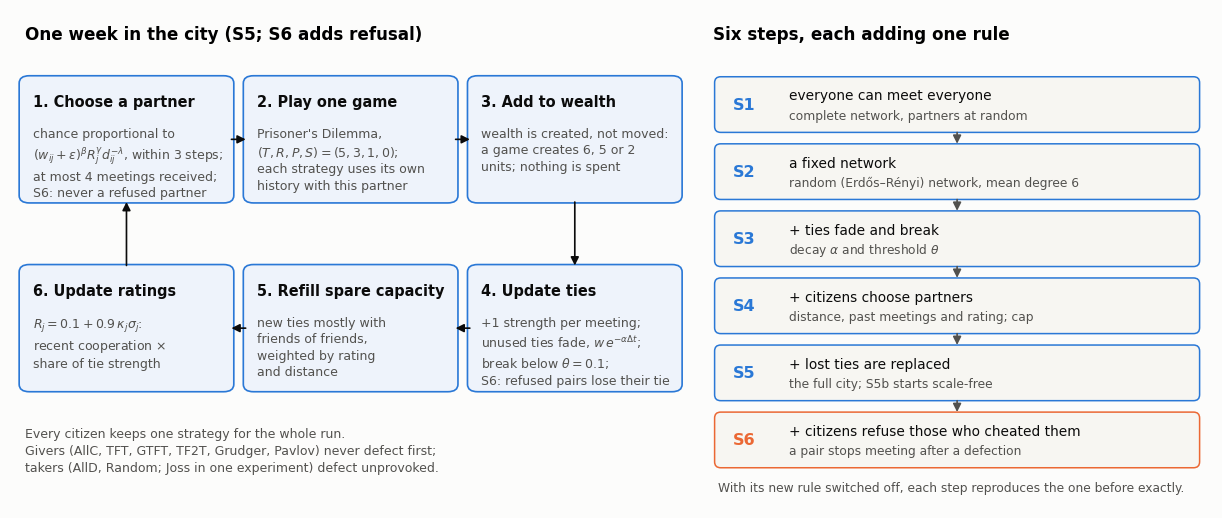

In [2]:
from utilities.model_diagram import model_diagram

fig = model_diagram()
P.save(fig, "model_diagram")
plt.show()

## Explore One City

**Purpose and layout:** To show how one city changes week by week, for any scenario and mix of
givers and takers. Choose the settings and press **Run**; the play button and the week slider then
step through the city every 10 weeks. Each run is one city of 60 citizens over 300 weeks and takes
a few seconds. Left: the city. Blue citizens are givers and orange are takers, the size of a
citizen is its wealth, the width of a line is the strength of the tie, and a citizen with no ties
sits on the outer ring. Right, from the top: wealth per person for givers, takers and everyone; the
Gini coefficient of wealth; and the share of takers with no ties. The grey line marks the week shown
on the left.

| Control | What it changes |
|---|---|
| Scenario | S1 to S6, as in *Scenarios* |
| Giver share | the share of givers, `f` |
| Refusal lasts | how many weeks a pair stays closed after a defection (`W`); used only in S6 |
| Joss among the takers | adds Joss as a third kind of taker, in equal numbers with AllD and Random |
| Seed | a different starting city |

One run shows how a single city unfolds, not how typical that is. The later sections average 5
cities per setting for that. The controls need a running Jupyter kernel. In a static copy of the
notebook, such as on GitHub, they do not appear; *One City Over Time* shows the same kind of city as
an animation.

**Settings worth comparing:** in the city that opens with the default seed (20260918):

1. **S5 against S6, giver share 0.5:** in S5 every taker keeps its ties. In S6, 73% of takers have
   no ties by week 50 and all of them by week 100, and the Gini at week 300 is twice as high (0.48
   against 0.24).
2. **S6 with a refusal that lasts 52 weeks:** takers are cut off at first (73% with no ties at week
   50), then most return as the refusals end (13% with no ties at week 300).
3. **S6 with Joss among the takers:** at week 300, half of the Joss citizens still have ties,
   against one in ten Random citizens and none of the AllD citizens.
4. **S1 against S5, giver share 1.0:** nobody cheats in either city, and both end with the same
   wealth per person (1,800), but the Gini is 0.015 in S1 and 0.22 in S5.

In [3]:
from utilities.explorer import explore

# The seven scenarios as (stage preset, settings). The experiment below runs the same ones.
SCENARIOS = {
    "S1 well-mixed":     ("M0", {}),
    "S2 static network": ("M1", {}),
    "S3 ties fade":      ("M2", {}),
    "S4 chosen partners": ("M3", {}),
    "S5 full city":      ("M4", {}),
    "S5b scale-free":    ("M4", {"topology.name": "barabasi_albert"}),
    "S6 refusal":        ("M5", {}),
}
explore(SCENARIOS, n_agents=60, n_rounds=300, every=10)

Controls for one city; they need a running Jupyter kernel.

## Checks

Before reading any result, we check the model in three ways. First, each step must reproduce the
step before exactly when its new rule is switched off, and the bookkeeping must hold. Second,
results that can be worked out by hand from the payoffs must come out of the simulation. Third,
extreme settings must not break the model. The checks use small cities of 60 citizens over 120
weeks, so they run quickly.

In [4]:
small = {"population.n_agents": 60, "run.n_rounds": 120}

# S3 without decay or severance is S2; S5 without severance is S4. Identical agent by agent.
s2 = trace(Simulation(stage("M1", **small), root_seed=5, repeat=0))
s3_off = trace(Simulation(stage("M2", **{**small, "ties.decay_rate": 0.0, "ties.severance_threshold": 0.0}), root_seed=5, repeat=0))
check(same_run(s2, s3_off), "S3 with no decay and no severance reproduces S2 exactly")

s4 = trace(Simulation(stage("M3", **{**small, "ties.severance_threshold": 0.0}), root_seed=8, repeat=0))
s5_off = trace(Simulation(stage("M4", **{**small, "ties.severance_threshold": 0.0}), root_seed=8, repeat=0))
check(same_run(s4, s5_off), "S5 with no severance reproduces S4 exactly")

sim = Simulation(stage("M4", **small), root_seed=8, repeat=1, instruments=("core",))
out = sim.run().outputs["core"]
s = sim.state
check(np.isclose(s.wealth.sum(), s.payoff_total.sum()), "every unit of wealth comes from a game payoff")
check((s.degree() <= s.capacity).all(), "no agent holds more ties than its capacity")
check(np.array_equal(s.adjacency, s.adjacency.T) and not s.adjacency.diagonal().any(), "ties are mutual, and nobody is tied to themselves")
check(out["max_received"].max() <= stage("M4").encounter.max_received, "no agent is met more often than the cap allows")

# S6 without refusal is S5.
s5 = trace(Simulation(stage("M4", **small), root_seed=8, repeat=0))
s6_off = trace(Simulation(stage("M5", **{**small, "encounter.refusal": "none"}), root_seed=8, repeat=0))
check(same_run(s5, s6_off), "S6 with refusal switched off reproduces S5 exactly")

# Under refusal a pair never meets again once either side has defected on the other.
from source.encounter import refused
walk = Simulation(stage("M5", **small), root_seed=8, repeat=1, instruments=("core",))
repeat_games = 0
for _ in range(small["run.n_rounds"]):
    closed = refused(walk.state, walk.cfg).copy()
    record = walk.run_round().record
    repeat_games += int(closed[record.initiator, record.partner].sum())
check(repeat_games == 0, "under refusal, no pair plays again after a defection between them")
check(not (walk.state.adjacency & refused(walk.state, walk.cfg)).any(),
      "under refusal, no tie survives between two agents who have walked away from each other")

# Joss is Tit-for-Tat with an unprovoked defection one game in ten, so against a partner who
# always cooperates it should cooperate about 90% of the time.
joss_city = Simulation(stage("M1", **{**small, "population.giver_fraction": 0.5,
                                      "population.giver_composition": {"allc": 1.0},
                                      "population.taker_composition": {"joss": 1.0}}),
                       root_seed=8, repeat=0, instruments=("core",))
giver = joss_city.state.giver
joss_coop = joss_moves = 0
for _ in range(small["run.n_rounds"]):
    r = joss_city.run_round().record
    for actor, partner, move in ((r.initiator, r.partner, r.move_i), (r.partner, r.initiator, r.move_j)):
        against_allc = ~giver[actor] & giver[partner]
        joss_coop += int((move[against_allc] == 0).sum())
        joss_moves += int(against_allc.sum())
check(0.87 < joss_coop / joss_moves < 0.93,
      f"Joss cooperates with unconditional cooperators {joss_coop / joss_moves:.3f} of the time")

PASS  S3 with no decay and no severance reproduces S2 exactly


PASS  S5 with no severance reproduces S4 exactly
PASS  every unit of wealth comes from a game payoff
PASS  no agent holds more ties than its capacity
PASS  ties are mutual, and nobody is tied to themselves
PASS  no agent is met more often than the cap allows


PASS  S6 with refusal switched off reproduces S5 exactly
PASS  under refusal, no pair plays again after a defection between them
PASS  under refusal, no tie survives between two agents who have walked away from each other


PASS  Joss cooperates with unconditional cooperators 0.906 of the time


**Results worked out by hand:** for some cities the outcome follows from the payoffs alone. Two
cooperators get `R = 3` each, two defectors `P = 1` each, and a cooperator and a defector get
`S = 0` and `T = 5`. So a city of cooperators must hold exactly 3 per game played, a city of AllD
exactly 1 per game, and every game must create 6, 5 or 2 units of wealth. In S1 with no cap on
meetings, every citizen plays exactly two games a week. In a well-mixed city of AllD and Random
(half each), where nobody can meet themselves, the expected payoff per game is
$\frac{49}{99}\cdot\frac{1 + 2.25}{2} + \frac{50}{99}\cdot\frac{3 + 0.5}{2} = 1.688$.

In [5]:
def finished(stage_name, seed=0, **overrides):
    sim = Simulation(stage(stage_name, **overrides), root_seed=R.DEFAULT_SEED, repeat=seed, instruments=("core",))
    sim.run()
    return sim.state

givers = finished("M0", **small, **{"population.giver_fraction": 1.0})
check(np.array_equal(givers.wealth, 3 * givers.games_played) and givers.wealth.mean() == 3 * 2 * small["run.n_rounds"],
      "a well-mixed city of givers holds exactly 3 per game, at 2 games a week")
defectors = finished("M4", **small, **{"population.giver_fraction": 0.0, "population.taker_composition": {"alld": 1.0}})
check(np.array_equal(defectors.wealth, 1 * defectors.games_played), "a city of AllD holds exactly 1 per game")
flipped = finished("M4", **small, **{"population.giver_fraction": 1.0, "population.giver_composition": {"allc": 1.0},
                                     "game.noise": 1.0})
check(np.array_equal(flipped.wealth, 1 * flipped.games_played),
      "AllC with every move flipped by noise plays as AllD: exactly 1 per game")

mixed = Simulation(stage("M4", **{**small, "population.giver_fraction": 0.5}), root_seed=R.DEFAULT_SEED, repeat=0)
created = set()
for _ in range(small["run.n_rounds"]):
    r = mixed.run_round().record
    created |= set(np.unique(r.payoff_i + r.payoff_j).tolist())
check(created <= {2.0, 5.0, 6.0}, f"every game creates 2, 5 or 6 units of wealth (seen: {sorted(created)})")

# Five full-size cities, so the sampling error of the mean payoff is small enough to test against.
full_size = {"population.n_agents": 100, "run.n_rounds": 500, "population.giver_fraction": 0.0}
per_game = [s.wealth.sum() / s.games_played.sum() for s in (finished("M0", seed, **full_size) for seed in range(5))]
check(abs(np.mean(per_game) - 1.688) < 3 * np.std(per_game, ddof=1) / np.sqrt(len(per_game)) + 0.002,
      f"a well-mixed city of AllD and Random earns {np.mean(per_game):.4f} per game against 1.688 expected")

PASS  a well-mixed city of givers holds exactly 3 per game, at 2 games a week
PASS  a city of AllD holds exactly 1 per game


PASS  AllC with every move flipped by noise plays as AllD: exactly 1 per game


PASS  every game creates 2, 5 or 6 units of wealth (seen: [2.0, 5.0, 6.0])


PASS  a well-mixed city of AllD and Random earns 1.6861 per game against 1.688 expected


**Extreme settings:** the model must not break at the edges of its settings. Each case below either
has a known answer, or must at least keep the bookkeeping correct: no citizen above its tie
capacity, every tie shared by both citizens, every unit of wealth coming from a game, and no
negative wealth.

In [6]:
def sound(state):
    return ((state.degree() <= state.capacity).all() and np.array_equal(state.adjacency, state.adjacency.T)
            and np.isclose(state.wealth.sum(), state.payoff_total.sum()) and (state.wealth >= 0).all()
            and not np.isnan(state.wealth).any())

# All givers: nobody ever defects, so refusal has nothing to act on and S6 is S5 exactly.
all_givers = {**small, "population.giver_fraction": 1.0}
check(same_run(trace(Simulation(stage("M4", **all_givers), root_seed=5, repeat=0)),
               trace(Simulation(stage("M5", **all_givers), root_seed=5, repeat=0))),
      "with no takers, S6 reproduces S5 exactly")

# All takers under refusal: every pair eventually closes, every agent ends alone and wealth stops.
alone = Simulation(stage("M5", **{**small, "population.giver_fraction": 0.0, "run.n_rounds": 200}),
                   root_seed=R.DEFAULT_SEED, repeat=0, instruments=("core",))
history = alone.run().outputs["core"]
check(history["isolated"][-1] == small["population.n_agents"] and history["mean_wealth"][-1] == history["mean_wealth"][-50],
      "with only takers and refusal, every agent ends with no ties and wealth stops growing")

EDGES = {
    "4 agents, cap of 1, reach of 1": {"population.n_agents": 4, "encounter.max_received": 1, "encounter.d_max": 1},
    "5 agents, mean degree 2": {"population.n_agents": 5, "topology.mean_degree": 2},
    "refusal forgiven after 1 week": {"encounter.refusal_memory": 1},
    "refusal by reputation": {"encounter.refusal": "reputation"},
    "ties fading almost at once": {"ties.decay_rate": 2.0},
    "almost no contact without a tie": {"encounter.eps": 1e-9},
    "scale-free city with refusal": {"topology.name": "barabasi_albert"},
}
for label, overrides in EDGES.items():
    check(sound(finished("M5", **{**small, "population.giver_fraction": 0.5, "run.n_rounds": 60, **overrides})),
          f"bookkeeping holds: {label}")

check(same_run(trace(Simulation(stage("M5", **small), root_seed=5, repeat=0)),
               trace(Simulation(stage("M5", **small), root_seed=5, repeat=0))),
      "the same seed reproduces a run exactly")

PASS  with no takers, S6 reproduces S5 exactly


PASS  with only takers and refusal, every agent ends with no ties and wealth stops growing
PASS  bookkeeping holds: 4 agents, cap of 1, reach of 1
PASS  bookkeeping holds: 5 agents, mean degree 2
PASS  bookkeeping holds: refusal forgiven after 1 week


PASS  bookkeeping holds: refusal by reputation
PASS  bookkeeping holds: ties fading almost at once


PASS  bookkeeping holds: almost no contact without a tie
PASS  bookkeeping holds: scale-free city with refusal


PASS  the same seed reproduces a run exactly


## Experiment: Changing the Mix of Givers and Takers

We run every scenario at six giver fractions with 5 seeds each: 210 cities. With 8 parallel
workers this takes about two minutes, and the whole notebook about fifteen.

Most figures below show cities at week 500. *Do the Cities Settle?* shows that in S1 to S5 the
averages of income, and of how evenly income is shared, stop changing well before week 500, so the
state at week 500 describes where these cities end up. S6 is still changing at week 500, and its
section also shows how it changes over time.

In [7]:
# SCENARIOS is defined in *Explore One City*.
# The figures in this section compare the first five steps; S6 has its own section below.
BASE = [name for name in SCENARIOS if name != "S6 refusal"]
# S2 and S3 produce identical cities, so S3 is drawn dashed on top of S2.
LINESTYLE = {"S3 ties fade": "--"}
FRACTIONS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
SETTINGS = {"population.n_agents": 100, "run.n_rounds": 500}
# Every seed count in the notebook comes from here, including the figure captions.
N_SEEDS = 5
# Half the cores: a full machine for the length of the notebook is more than some hosts tolerate.
WORKERS = max(1, (os.cpu_count() or 2) // 2)

sweep = R.sweep(SCENARIOS, FRACTIONS, n_seeds=N_SEEDS, timeseries=True, workers=WORKERS,
                **SETTINGS)
runs = sweep.runs
print(f"{len(runs)} cities: {runs['scenario'].nunique()} scenarios x {len(FRACTIONS)} giver fractions x {N_SEEDS} seeds")
print(f"histories kept: {len(sweep.core):,} core rows, {len(sweep.structure):,} structure rows")
runs.head(3)

210 cities: 7 scenarios x 6 giver fractions x 5 seeds
histories kept: 21,000 core rows, 10,710 structure rows


,scenario,repeat,giver_fraction,topology,mean_wealth,median_wealth,total_wealth,mean_income,gini,top10_share,...,realised_degree_taker,isolated_giver,isolated_taker,clustering,clustering_giver,clustering_taker,transitivity,mean_path_length,n_components,assortativity_slope
0,S1 well-mixed,0,0.0,complete,1692.62,1686.0,169262.0,3.3980,0.105469,0.124824,...,39.66,0.0,0.0,1.0,NaN,1.0,1.0,1.0,1.0,NaN
1,S1 well-mixed,1,0.0,complete,1689.42,1642.5,168942.0,3.3882,0.106915,0.124552,...,40.02,0.0,0.0,1.0,NaN,1.0,1.0,1.0,1.0,NaN
2,S1 well-mixed,2,0.0,complete,1682.70,1671.0,168270.0,3.3504,0.108695,0.126351,...,39.94,0.0,0.0,1.0,NaN,1.0,1.0,1.0,1.0,NaN


### Prosperity, Inequality and Cooperation

This figure compares S1 to S5b, the scenarios the hypotheses were written for. S6 is compared with
S5 in its own section. S2 and S3 produce identical cities, so S3 is drawn dashed, with open
markers, on top of S2.

**Purpose and layout:** To see how the mix of givers and takers changes a city's wealth, its inequality, and whether cheating pays, in each scenario without refusal. Three panels, each plotted against the giver fraction (0 to 1). Each line is one
scenario, and each point is the mean of `N_SEEDS` cities, with error bars of one standard error.
Left: wealth per person at week 500, with the median for S5 dashed. Centre: the Gini coefficient of
wealth at week 500. Right: a taker's average payoff per game minus a giver's; it only exists where
both classes are present. We show week 500 rather than the change over time, because the question
is how the mix of givers and takers changes where a city ends up.

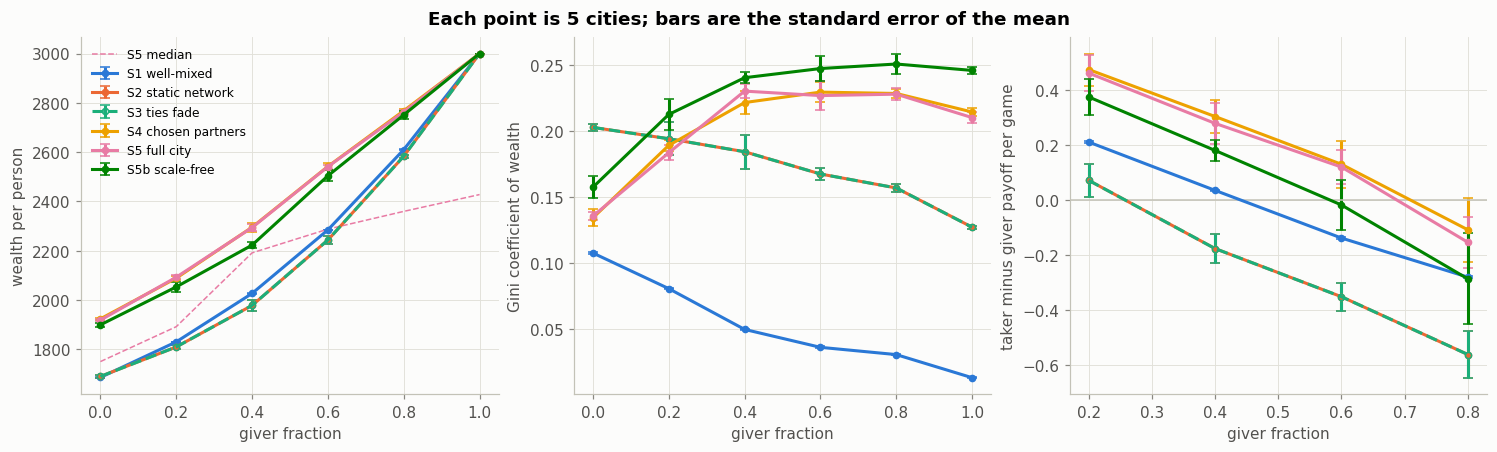

gini                                 \
scenario       S1 well-mixed S2 static network S3 ties fade   
giver_fraction                                                
0.0                    0.108             0.203        0.203   
0.2                    0.081             0.194        0.194   
0.4                    0.050             0.184        0.184   
0.6                    0.036             0.168        0.168   
0.8                    0.031             0.157        0.157   
1.0                    0.013             0.127        0.127   

                                                                mean_wealth  \
scenario       S4 chosen partners S5 full city S5b scale-free S1 well-mixed   
giver_fraction                                                                
0.0                         0.134        0.136          0.158      1686.050   
0.2                         0.189        0.184          0.213      1830.362   
0.4                         0.222        0.230          0.241      2026.800   
0.6                         0.230        0.227          0.248      2284.600   
0.8                         0.229        0.228          0.251      2610.214   
1.0                         0.215        0.210          0.246      3000.000   

                                                                               \
scenario       S2 static network S3 ties fade S4 chosen partners S5 full city   
giver_fraction                                                                  
0.0                     1690.078     1690.078           1923.750     1918.346   
0.2                     1809.714     1809.714           2088.758     2092.656   
0.4                     1978.160     1978.160           2295.462     2294.066   
0.6                     2243.618     2243.618           2541.958     2540.986   
0.8                     2583.390     2583.390           2768.052     2763.264   
1.0                     3000.000     3000.000           3000.000     3000.000   

                               
scenario       S5b scale-free  
giver_fraction                 
0.0                  1899.370  
0.2                  2053.278  
0.4                  2222.834  
0.6                  2504.038  
0.8                  2751.082  
1.0                  3000.000

In [8]:
means = R.cell_means(runs, ["mean_wealth", "median_wealth", "gini", "coop_rate", "payoff_gap"])
colours = dict(zip(SCENARIOS, P.SERIES))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4))
panels = [("mean_wealth", "wealth per person"), ("gini", "Gini coefficient of wealth"),
          ("payoff_gap", "taker minus giver payoff per game")]
for ax, (metric, label) in zip(axes, panels):
    for name in BASE:
        rows = means[means["scenario"] == name]
        ax.errorbar(rows["giver_fraction"], rows[metric], yerr=rows[f"{metric}_se"],
                    color=colours[name], marker="o", markersize=4, capsize=3, label=name,
                    linestyle=LINESTYLE.get(name, "-"), mfc="none" if name in LINESTYLE else None)
    ax.set(xlabel="giver fraction", ylabel=label)
axes[0].plot(means[means["scenario"] == "S5 full city"]["giver_fraction"],
             means[means["scenario"] == "S5 full city"]["median_wealth"],
             color=colours["S5 full city"], linewidth=1, linestyle="--", label="S5 median")
axes[2].axhline(0, color=P.AXIS, linewidth=1)
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle(f"Each point is {N_SEEDS} cities; bars are the standard error of the mean", fontweight="bold")
P.save(fig, "sweep")
plt.show()

means[means["scenario"].isin(BASE)].pivot_table(index="giver_fraction", columns="scenario", values=["mean_wealth", "gini"]).round(3)

> **Insight 1:** wealth per person rises faster than the share of givers. In S5, going from 0% to
> 40% givers adds 376 to wealth per person, and going from 60% to 100% adds 459. The test in
> *Hypothesis Check* confirms the bend (H1).
>
> **Why this happens in the model:** a game between two givers creates 6 units of wealth, a game
> between a giver and a taker creates 5, and a game between two takers creates 2. The number of
> games between two givers grows faster than the number of givers, because each extra giver also
> gives every other giver one more giver to meet.
>
> **Model compared to expectations based on reality:** this fits the idea that cooperating pays
> more when more people around you cooperate. That could be one reason why measured effects of
> social capital vary so much between places [1], though that study does not test it. The
> giver share where the bend happens (0.29) depends on our payoffs and on who can meet whom, so it
> should not be read as a real-world threshold.

### Who Ends Up Connected to Whom

This figure leaves out S1 and S6. In S1 every citizen is tied to every other, so which classes are
tied together is fixed by the population. In S6 most takers end with no ties, so class
assortativity cannot be calculated; S6 has its own section. S2 and S3 produce identical cities, so
S3 is drawn dashed on top of S2.

**Purpose and layout:** To see whether givers end up tied mostly to givers, and whether takers are left with fewer partners (H3). Two panels for mixed cities only (giver fraction 0.2 to 0.8), because both classes
must be present for these measures. Left: class assortativity of the network at week 500.
Positive means givers are tied mostly to givers; negative means ties link givers and takers more
often than chance. Right: the number of different partners a taker played in the last 100 weeks,
minus the number a giver played. Negative means takers are met by fewer citizens. We show the end
of the run because we want to know which network each city ends up with.

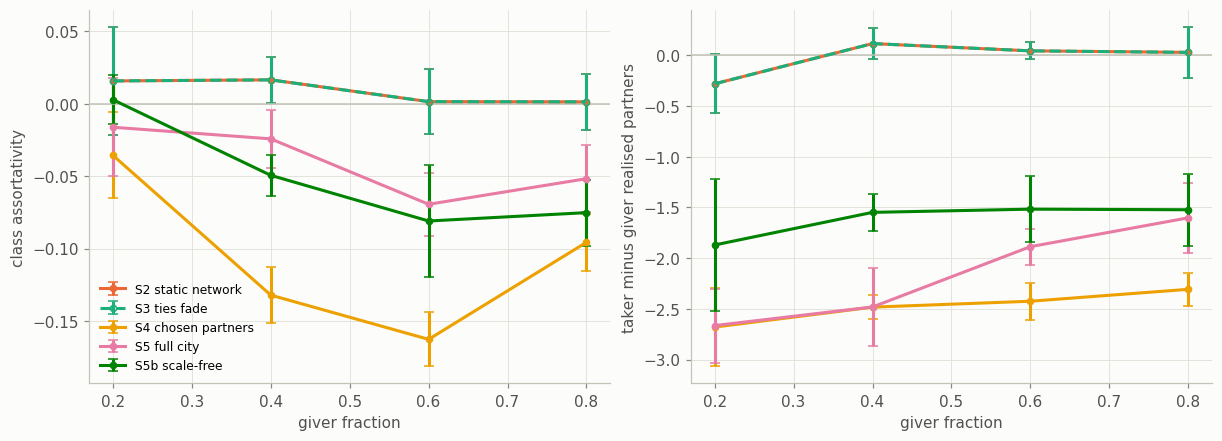

assortativity_class                                 \
scenario             S1 well-mixed S2 static network S3 ties fade   
giver_fraction                                                      
0.2                          -0.01             0.016        0.016   
0.4                          -0.01             0.017        0.017   
0.6                          -0.01             0.002        0.002   
0.8                          -0.01             0.001        0.001   

                                                                partner_gap  \
scenario       S4 chosen partners S5 full city S5b scale-free S1 well-mixed   
giver_fraction                                                                
0.2                        -0.036       -0.016          0.003         0.512   
0.4                        -0.132       -0.024         -0.049        -0.425   
0.6                        -0.163       -0.069         -0.081         0.125   
0.8                        -0.096       -0.052         -0.075         0.075   

                                                                               \
scenario       S2 static network S3 ties fade S4 chosen partners S5 full city   
giver_fraction                                                                  
0.2                       -0.280       -0.280             -2.680       -2.665   
0.4                        0.117        0.117             -2.483       -2.482   
0.6                        0.045        0.045             -2.425       -1.887   
0.8                        0.030        0.030             -2.308       -1.602   

                               
scenario       S5b scale-free  
giver_fraction                 
0.2                    -1.870  
0.4                    -1.548  
0.6                    -1.517  
0.8                    -1.523

In [9]:
structure = runs.assign(partner_gap=runs["realised_degree_taker"] - runs["realised_degree_giver"],
                        weight_gap=runs["weight_taker"] - runs["weight_giver"])
mixed = structure[structure["giver_fraction"].between(0.15, 0.85)]
struct_means = R.cell_means(mixed, ["assortativity_class", "partner_gap", "weight_gap"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
for ax, (metric, label) in zip(axes, [("assortativity_class", "class assortativity"),
                                      ("partner_gap", "taker minus giver realised partners")]):
    for name in ["S2 static network", "S3 ties fade", "S4 chosen partners", "S5 full city", "S5b scale-free"]:
        rows = struct_means[struct_means["scenario"] == name]
        ax.errorbar(rows["giver_fraction"], rows[metric], yerr=rows[f"{metric}_se"],
                    color=colours[name], marker="o", markersize=4, capsize=3, label=name,
                    linestyle=LINESTYLE.get(name, "-"), mfc="none" if name in LINESTYLE else None)
    ax.axhline(0, color=P.AXIS, linewidth=1)
    ax.set(xlabel="giver fraction", ylabel=label)
axes[0].legend(fontsize=8, loc="lower left")
P.save(fig, "connections")
plt.show()

struct_means[struct_means["scenario"].isin(BASE)].pivot_table(index="giver_fraction", columns="scenario",
                         values=["assortativity_class", "partner_gap"]).round(3)

> **Insight 2:** without refusal, takers are not pushed to the edge of the network. In S4 and S5,
> class assortativity is slightly negative (between -0.02 and -0.16), so ties link givers and takers
> a little more often than chance. Takers do end with fewer partners than givers: in S4, two to
> three fewer.
>
> **Why this happens in the model:** everyone, takers included, chooses partners by reputation,
> and givers have the best reputations. Before S6, a giver cannot decline a meeting. So takers keep
> meeting givers (the table in *What Each Step of the Model Changes* shows that 76% of a taker's
> games in S4 are against givers).
>
> **Model compared to expectations based on reality:** in experiments where people can change who
> they are connected to, they cut ties with people who defect and form new ties with cooperators
> [12]. So in a real city we would expect givers to be connected to givers more than they are
> here. The mixing here comes from the assumption that givers cannot refuse a meeting, which S6
> removes.

### Summary of the Sweep, Step by Step

- **S1, everyone can meet everyone:** wealth per person rises from 1,686 with no givers to 3,000
  with only givers. Inequality is the lowest of all scenarios (Gini 0.01 to 0.11), because every
  citizen has the same chance of meeting anyone.
- **S2, fixed network:** inequality is higher at every mix (Gini 0.13 to 0.20), because a citizen's
  results now depend on which neighbours it has. Takers gain less from cheating than in S1, because
  they keep meeting the same neighbours and the givers who retaliate punish them.
- **S3, fading ties:** identical to S2. No tie breaks, because neighbours meet every few weeks and a
  tie needs 46 weeks without a meeting to break.
- **S4, chosen partners:** wealth and cooperation rise, and inequality rises in mixed cities (Gini
  up to 0.23). Takers end with fewer partners than givers.
- **S5, lost ties replaced:** almost the same as S4 for wealth and inequality.
- **S5b, scale-free network:** the highest inequality without refusal (Gini 0.16 to 0.25). It stays
  high when almost everyone is a giver, where the random network becomes more equal again. A likely
  reason is that the few citizens who start with many ties keep being met more often; we have not
  measured this directly.
- **S6, refusal:** covered in *Letting Citizens Refuse (S6)*.

## Hypothesis Check

Each hypothesis is tested on S5, the full city without refusal, with decision rules fixed before the
runs. H1 compares a straight line with a line that bends once. The comparison uses BIC, a score that
rewards a better fit but penalises the extra parameters of the bent line; a difference above 10 is
treated as strong evidence [13], [14]. The other hypotheses use 95% bootstrap
intervals over seeds [15]. We then apply the same rules to S6.

In [10]:
from utilities import stats as S


def hypothesis_table(scenario):
    full = runs[runs["scenario"] == scenario].rename(columns={"giver_fraction": "population.giver_fraction"})
    # A fresh stream per test, so each verdict depends only on the runs and its own seed.
    h1 = S.h1_threshold(full, rng=np.random.default_rng(1))
    h2 = S.h2_decoupling(full, rng=np.random.default_rng(2))
    h3 = S.h3_segregation(full, fractions=FRACTIONS[1:-1], rng=np.random.default_rng(3))
    h4 = S.h4_equal_poverty(full, rng=np.random.default_rng(4))
    return pd.DataFrame([
        {"hypothesis": "H1 prosperity threshold", "test": "two-segment fit beats a line, steeper above the break",
         "result": f"BIC difference {h1['delta_bic']:.0f}, break at f = {h1['break']:.2f}", "verdict": h1["verdict"]},
        {"hypothesis": "H2 prosperity and equality decouple", "test": "Gini and wealth rise together above f = 0.5",
         "result": f"Spearman(f, Gini) = {h2['spearman']:.2f}", "verdict": h2["verdict"]},
        {"hypothesis": "H3 emergent segregation", "test": "assortativity rises; takers keep fewer, weaker ties",
         "result": f"assortativity slope {h3['slope'][0]:.1e}, partner gap {h3['degree_gap'][0]:.2f}, weight gap {h3['weight_gap'][0]:.2f}",
         "verdict": h3["verdict"]},
        {"hypothesis": "H4 the poverty trap is equal", "test": "taker cities poorer, not more unequal",
         "result": f"median wealth gap {h4['median_gap'][0]:.0f}, Gini gap {h4['gini_gap'][0]:.3f}", "verdict": h4["verdict"]},
    ]).set_index("hypothesis")


with pd.option_context("display.max_colwidth", 90):
    display(hypothesis_table("S5 full city"))
# The same decision rules on the city whose citizens can refuse, for comparison in the next sections.
hypothesis_table("S6 refusal")[["result", "verdict"]]

,test,result,verdict
hypothesis,,,
H1 prosperity threshold,"two-segment fit beats a line, steeper above the break","BIC difference 18, break at f = 0.29",supported
H2 prosperity and equality decouple,Gini and wealth rise together above f = 0.5,"Spearman(f, Gini) = 0.56",inconclusive
H3 emergent segregation,"assortativity rises; takers keep fewer, weaker ties","assortativity slope -9.3e-05, partner gap -2.16, weight gap -3.87",inconclusive
H4 the poverty trap is equal,"taker cities poorer, not more unequal","median wealth gap -573, Gini gap -0.060",supported


,result,verdict
hypothesis,,
H1 prosperity threshold,"BIC difference 91, break at f = 0.50",inconclusive
H2 prosperity and equality decouple,"Spearman(f, Gini) = -0.14",inconclusive
H3 emergent segregation,"assortativity slope nan, partner gap -6.68, we...",inconclusive
H4 the poverty trap is equal,"median wealth gap -2091, Gini gap 0.049",refuted


**Key findings:** The first table is S5. H1 and H4 are supported; H2 and H3 are
inconclusive.

- **H1 is supported:** the bent line fits better than a straight line (BIC difference 18, above
  10), and the bend is at a giver share of 0.29.
- **H2 is inconclusive:** the Gini rises steeply while takers are the majority (+0.048 and +0.046
  over the first two steps of 0.2), stays level in the middle (-0.003 from 0.4 to 0.6 and +0.001
  from 0.6 to 0.8), and falls when the last takers go (-0.018 from 0.8 to 1). H2 is supported only
  if inequality and wealth rise together above `f = 0.5`, which they do not. It is refuted only if
  the Gini falls as givers increase, which it does not either (rank correlation +0.56). Prosperity
  and equality do separate, but in the middle of the range, not in the richest cities.
- **H3 is inconclusive, because its two parts disagree:** takers do end with fewer partners (2.2
  fewer) and weaker ties (3.9 weaker), but class assortativity is negative and its trend over the
  last 100 weeks is close to zero (-9.3e-05 per week). Takers are left with less, but the classes
  do not separate.
- **H4 is supported:** taker-dominated cities are poorer (median wealth 573 lower) and more equal
  (Gini 0.060 lower).

**The same tests on S6** (second table):

- **H1 is not supported:** a bent line still fits better, but it bends the other way. Each extra 20%
  of givers adds a little less wealth than the one before (637, 601, 559, 520 and 478 per person),
  so there is no threshold.
- **H2 is inconclusive:** the Gini falls from 0.564 at 20% givers to 0.323 at 80%, but it is low when there are no givers at all (0.067), so it does not fall steadily with the giver share (rank correlation -0.14).
- **H3 cannot be tested:** class assortativity cannot be calculated once takers hold no ties.
- **H4 is refuted:** taker-dominated cities are poorer (median wealth 2,091 lower) and more
  unequal (Gini 0.049 higher).

*Letting Citizens Refuse (S6)* explains these differences.

## Extended Analysis

The sweep reports each city at week 500. This section uses the same 210 runs to answer five more
questions:

1. **Do the cities settle?** If not, the state at week 500 would depend on when we stopped.
2. **What does each step of the model change?** Each step adds one rule, so its effect can be
   measured directly.
3. **Does clustering matter?** H2 assumes cooperation depends on clusters.
4. **Where does inequality come from when nobody is ever cheated?**
5. **What changes when citizens can refuse?** S6 against S5, how long a refusal lasts, what the Gini
   coefficient does and does not show, and a taker that cooperates most of the time.

### Do the Cities Settle?

Wealth cannot settle in this model. It is never spent, so it keeps growing for as long as the run
lasts. What can settle is income: how much wealth the city produces each week, and how evenly that
income is shared. The `steady_state` check in `source/experiment.py` therefore tests whether mean
income and the Gini of income are still trending over the last 100 weeks, not whether wealth is.

**Purpose and layout:** To check whether the cities reach a steady state, so that their state at week 500 can stand for where they end up. Four panels for cities with 60% givers, each plotted against the week. Each line is
a scenario's mean over seeds, with a band of one standard error. From left: wealth per person; the
Gini of wealth; the Gini of income over the last 25 weeks; and the share of moves that were
cooperative. Here the change over time is the point, so we plot every week. We show one mix, 60%
givers, so that both classes are common and the lines are readable; the printed check below covers
every city in the sweep. S3 is left out because it is identical to S2.

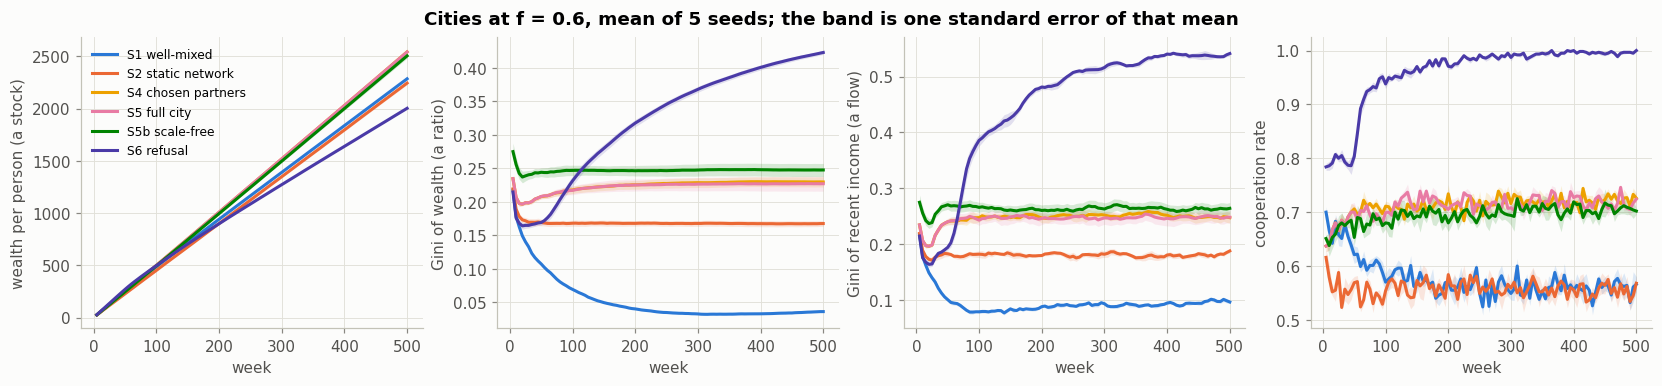

share of cities settled by week 500, all giver fractions:
scenario
S1 well-mixed         0.73
S2 static network     0.70
S3 ties fade          0.70
S4 chosen partners    0.57
S5 full city          0.63
S5b scale-free        0.77
S6 refusal            0.60


gini        income_gini        mean_wealth          
round                 250    500         250    500         250       500
scenario                                                                 
S1 well-mixed       0.035  0.036       0.090  0.097    1165.038  2284.600
S2 static network   0.168  0.168       0.179  0.188    1123.670  2243.618
S3 ties fade        0.168  0.168       0.179  0.188    1123.670  2243.618
S4 chosen partners  0.227  0.230       0.250  0.248    1262.682  2541.958
S5 full city        0.226  0.227       0.249  0.248    1263.444  2540.986
S5b scale-free      0.247  0.248       0.259  0.264    1244.964  2504.038
S6 refusal          0.346  0.423       0.507  0.541    1086.014  2002.224

In [11]:
LADDER = ["S1 well-mixed", "S2 static network", "S3 ties fade", "S4 chosen partners", "S5 full city", "S6 refusal"]
# S3 is left out because it is identical to S2.
SHOWN = ["S1 well-mixed", "S2 static network", "S4 chosen partners", "S5 full city", "S5b scale-free", "S6 refusal"]

# One giver fraction at a time: averaging across the mix would blend cities that differ by design.
mid_core = sweep.core[np.isclose(sweep.core["giver_fraction"], 0.6)]
convergence = R.series_means(mid_core, ["mean_wealth", "gini", "income_gini", "coop_rate"])

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
panels = [("mean_wealth", "wealth per person (a stock)"), ("gini", "Gini of wealth (a ratio)"),
          ("income_gini", "Gini of recent income (a flow)"), ("coop_rate", "cooperation rate")]
for ax, (metric, label) in zip(axes, panels):
    P.over_time(ax, convergence, metric, SHOWN, colours, ylabel=label)
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle(f"Cities at f = 0.6, mean of {N_SEEDS} seeds; the band is one standard error of that mean",
             fontweight="bold")
P.save(fig, "settling")
plt.show()

# The figure shows one mix; this covers every city in the sweep. A city counts as settled when, over its
# last 100 weeks, neither its mean income nor the Gini of its income is still trending (see steady_state).
print("share of cities settled by week 500, all giver fractions:")
print(runs.groupby("scenario")["steady_state"].mean().round(2).to_string())

convergence[convergence["round"].isin([250, 500])].pivot_table(
    index="scenario", columns="round", values=["mean_wealth", "gini", "income_gini"]).round(3)

**Key findings:** Wealth per person doubles between week 250 and week 500 in every scenario
(S5: 1,263 to 2,541), as expected when the same income is added every week. The other measures stop
changing well before the end in S1 to S5: in S5 the Gini of wealth moves from 0.226 to 0.227 between
week 250 and week 500, and the Gini of income from 0.249 to 0.248. Over all 210 cities, the `steady_state` check printed above the table counts between 57% and 77% of the cities in each scenario as settled (S1 73%, S2 70%, S4 57%, S5 63%, S5b 77%, S6 60%). The other cities still show a small trend in income, or in the Gini of income, over their last 100 weeks. With 100 citizens, weekly income is noisy, and the averaged lines in the figure are flat, so many of these trends are probably noise, but the check alone does not show that. Results at week 500 should therefore be read as close to a settled state, not exactly at one.

S6 behaves differently. Its Gini of income is still rising between week 250 and week 500 (0.507 to
0.541), because takers are still being cut off. Its results at week 500 describe a city that is
still changing.

**What this means for the results:** for S1 to S5 we report income-based measures averaged over the
last 100 weeks and wealth at week 500. For S6 we also show how it changes over time.

### What Each Step of the Model Changes

Each step adds one rule, and every scenario uses the same seeds. So we can run the same city under
two neighbouring steps and take the difference. For each of the 30 cities (6 giver fractions x 5
seeds), this difference is the effect of the added rule, without the luck of a different starting
city.

**Purpose and layout:** To measure what each rule adds, by running the same cities with and without it. Each row is one step of the model, and each bar is the average change in one
measure when the same cities are run with and without that step's rule. Blue bars are increases and
orange bars decreases; error bars are one standard error. From left: wealth per person, Gini of
wealth, cooperation rate, and a taker's payoff per game minus a giver's. S5b is not shown because it
is not a step: it changes the starting network, not a rule.

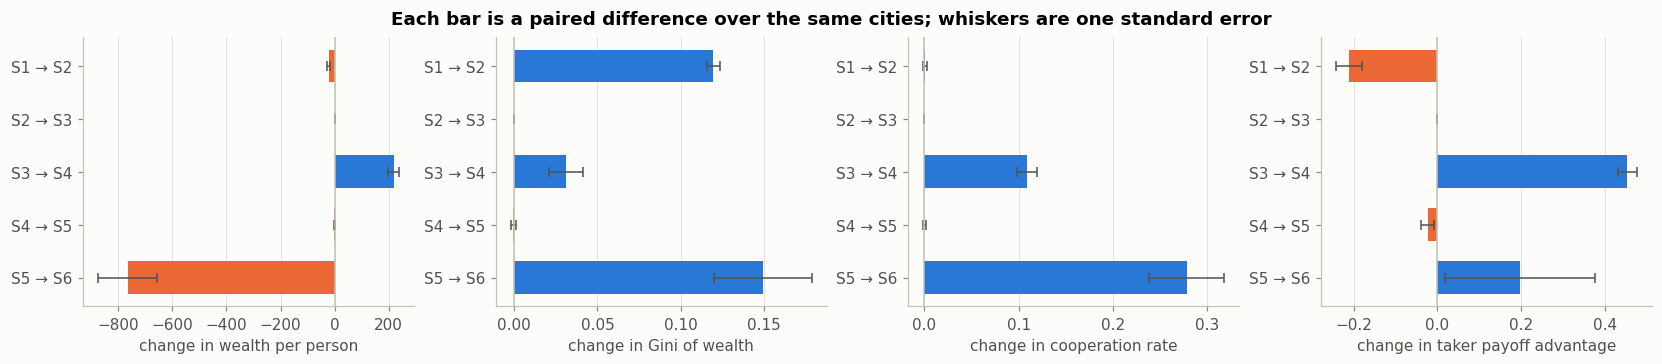

,metric,step,mean,se,n
0,mean_wealth,S1 → S2,-22.1777,5.7402,30
1,mean_wealth,S2 → S3,0.0000,0.0000,30
2,mean_wealth,S3 → S4,218.8367,20.0821,30
3,mean_wealth,S4 → S5,-1.4437,1.7096,30
4,mean_wealth,S5 → S6,-765.8300,108.6873,30
0,gini,S1 → S2,0.1194,0.0038,30
1,gini,S2 → S3,0.0000,0.0000,30
2,gini,S3 → S4,0.0308,0.0102,30
3,gini,S4 → S5,-0.0005,0.0016,30
4,gini,S5 → S6,0.1492,0.0294,30


In [12]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
panels = [("mean_wealth", "change in wealth per person"), ("gini", "change in Gini of wealth"),
          ("coop_rate", "change in cooperation rate"), ("payoff_gap", "change in taker payoff advantage")]
deltas = {}
# payoff_gap is undefined when a class is absent, so its panel pairs only the mixed cities.
for ax, (metric, label) in zip(axes, panels):
    deltas[metric] = R.stage_deltas(runs, metric, LADDER)
    P.delta_bars(ax, deltas[metric], xlabel=label)
fig.suptitle("Each bar is a paired difference over the same cities; whiskers are one standard error",
             fontweight="bold")
P.save(fig, "ladder_deltas")
plt.show()

pd.concat([t.assign(metric=m) for m, t in deltas.items()])[["metric", "step", "mean", "se", "n"]].round(4)

**Key findings:**

- **S1 to S2 (fixed network):** the Gini rises by 0.119 and wealth per person falls slightly (by 22,
  standard error 6). The cooperation rate does not change (+0.0008, standard error 0.0019). The
  taker payoff gap falls by 0.211 per game, because givers that retaliate now meet the same takers
  again. The network changes who gets the wealth, not how much cooperation there is.
- **S2 to S3 (fading ties):** exactly zero on every measure, because no tie fades enough to break.
  Fading does lower the strength of ties, and tie strength is part of how partners are chosen in S4,
  so this rule only has an effect once partners are chosen.
- **S3 to S4 (chosen partners):** the largest step without refusal. Wealth per person rises by 219,
  the cooperation rate by 0.109 and the Gini by 0.031. The taker payoff gap rises by 0.454 per game.
- **S4 to S5 (replacing lost ties):** wealth changes by -1.4 and the Gini by -0.0005, neither
  different from zero.
- **S5 to S6 (refusal):** wealth per person falls by 766 (standard error 109), the Gini rises by
  0.149 (standard error 0.029) and the cooperation rate by 0.278. Cooperation rises because the
  games that still happen are almost all between givers. Wealth falls because far fewer games
  happen.

The next table looks at the S3 to S4 step in detail, because it changes the most without refusal. It
compares S3 and S4 cities with half givers.

In [13]:
# Choice does not change how a taker plays; it changes who it plays. Every citizen weighs
# candidates by the partner's rating, and givers are the ones with high ratings.
def partner_mix_once(stage_name, repeat):
    cfg = stage(stage_name, **{**SETTINGS, "population.giver_fraction": 0.5})
    sim = Simulation(cfg, root_seed=R.DEFAULT_SEED, repeat=repeat, instruments=("core",))
    giver = sim.state.giver
    played = np.zeros((2, 2))                              # [actor is a giver, partner is a giver]
    for _ in range(cfg.run.n_rounds):
        record = sim.run_round().record
        if record.n_games == 0:
            continue
        gi, gj = giver[record.initiator], giver[record.partner]
        for actor, partner in ((gi, gj), (gj, gi)):        # both sides of every game
            for cls in (0, 1):
                played[cls, 1] += ((actor == bool(cls)) & partner).sum()
                played[cls, 0] += ((actor == bool(cls)) & ~partner).sum()
    share = played / played.sum(axis=1, keepdims=True)
    return {"a taker's games that are against givers": share[0, 1],
            "a giver's games that are against givers": share[1, 1],
            "mean popularity rating, givers": sim.state.rating[giver].mean(),
            "mean popularity rating, takers": sim.state.rating[~giver].mean()}


# The same seeds as the sweep, so these numbers carry their uncertainty like the rest.
def partner_mix(stage_name, n_seeds=N_SEEDS):
    seeds = pd.DataFrame([partner_mix_once(stage_name, repeat) for repeat in range(n_seeds)])
    return pd.DataFrame({"mean": seeds.mean(), "se": seeds.sem()})

mix = pd.concat({"S3 uniform draws": partner_mix("M2"),
                 "S4 chosen partners": partner_mix("M3")}, axis=1)
mix.round(3)

S3 uniform draws         \
                                                    mean     se   
a taker's games that are against givers            0.487  0.014   
a giver's games that are against givers            0.507  0.015   
mean popularity rating, givers                     1.000  0.000   
mean popularity rating, takers                     1.000  0.000   

                                        S4 chosen partners         
                                                      mean     se  
a taker's games that are against givers              0.764  0.012  
a giver's games that are against givers              0.594  0.008  
mean popularity rating, givers                       0.511  0.006  
mean popularity rating, takers                       0.166  0.003

**Key findings:** When partners are drawn with equal chance (S3), both classes play givers
about half the time (a taker 0.487, a giver 0.507), as expected with half givers. When partners are
chosen (S4), a taker plays givers in **76%** of its games, and a giver plays other givers in 59%.
Givers have ratings three times higher than takers (0.511 against 0.166), and every citizen,
including every taker, prefers higher-rated partners. Givers cannot refuse a meeting. A taker that
defects against a cooperator gets `T = 5`, the highest payoff, which is why the taker payoff gap
rises at this step. Every citizen still starts one meeting a week; what changes is who they choose.

> **Insight 3:** of all the rules added before S6, partner choice changes the city the most. A fixed
> network changes who gets the wealth but not how much cooperation there is; fading ties change
> nothing on their own; partner choice raises wealth, cooperation and inequality together.
>
> **Why this happens in the model:** partner choice is the only rule before S6 that lets a
> citizen's reputation affect how often it plays. Fading ties have no effect on their own because a
> tie used every few weeks never comes close to the 46 weeks it needs to break.
>
> **Model compared to expectations based on reality:** in real data, who people are connected to is
> more strongly linked to economic mobility than how tight-knit their networks are [2]. That study
> measures friendships, not how people choose them, so it supports the general idea that who you
> meet matters, not this specific rule. The lack of any
> effect from fading ties comes from our settings (weekly meetings and a slow fading rate), not
> from anything we would expect in a real city.

### Clustering and Connectivity

H2 assumes that cooperation depends on clusters, groups of citizens whose acquaintances also know
each other. We measure clustering in two ways. **Average clustering** is, for each citizen, the
share of pairs of its acquaintances who also know each other, averaged over citizens.
**Transitivity** is the same share counted over the whole city, which gives more weight to citizens
with many ties. We also track the average number of steps between citizens and the number of
separate pieces the network has broken into.

One limit applies before any result. In the literature, clustering helps cooperation because
cooperators in a cluster do better and are then copied by others [8], [9]. In
this model nobody ever changes strategy or copies anyone, so that process cannot happen here. A
correlation between clustering and cooperation across the sweep would also mostly reflect the mix
of givers, which sets the cooperation rate. So we ask a narrower question: with the same citizens,
does the arrangement of the ties matter?

**Purpose and layout:** To see how breaking and replacing ties changes the shape of the network over time. Three panels for cities with 60% givers, plotted against the week. Left: average
clustering. Centre: the average number of steps between citizens who can still reach each other.
Right: clustering for givers and takers separately, in S4. We plot the change over time because
breaking and replacing ties changes the network as the run goes on. S1 is left out because everyone
is tied to everyone (clustering is 1). S3 is left out because it is identical to S2. S6 is left out
of the figure because by the end most of its takers have no ties, so its averages describe only the
givers; its values are in the table.

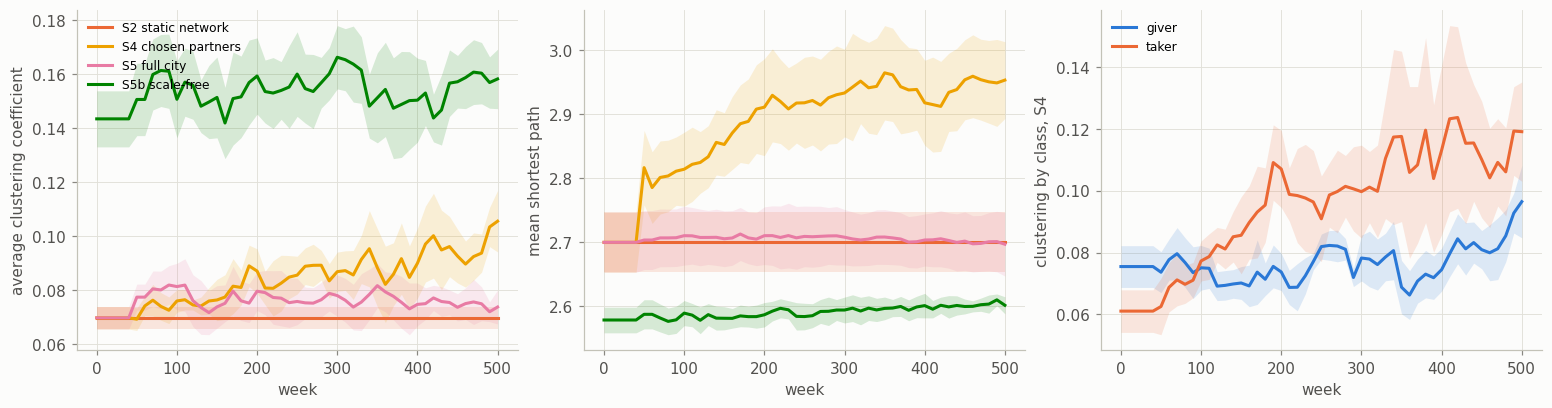

clustering        mean_path_length        n_components  \
round                     0      500              0      500          0     
scenario                                                                    
S1 well-mixed           1.000  1.000            1.000  1.000          1.0   
S2 static network       0.070  0.070            2.699  2.699          1.0   
S3 ties fade            0.070  0.070            2.699  2.699          1.0   
S4 chosen partners      0.070  0.105            2.699  2.953          1.0   
S5 full city            0.070  0.074            2.699  2.696          1.0   
S5b scale-free          0.143  0.158            2.578  2.601          1.0   
S6 refusal              0.070  0.065            2.699  2.453          1.0   

                          
round                500  
scenario                  
S1 well-mixed        1.0  
S2 static network    1.0  
S3 ties fade         1.0  
S4 chosen partners   1.4  
S5 full city         1.0  
S5b scale-free       1.0  
S6 refusal          39.8

In [14]:
mid_structure = sweep.structure[np.isclose(sweep.structure["giver_fraction"], 0.6)]
structure_ts = R.series_means(mid_structure, ["clustering", "clustering_giver", "clustering_taker",
                                              "transitivity", "mean_path_length", "n_components"])
NETWORKS = ["S2 static network", "S4 chosen partners", "S5 full city", "S5b scale-free"]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
P.over_time(axes[0], structure_ts, "clustering", NETWORKS, colours,
            ylabel="average clustering coefficient")
P.over_time(axes[1], structure_ts, "mean_path_length", NETWORKS, colours,
            ylabel="mean shortest path")
s4 = structure_ts[structure_ts["scenario"] == "S4 chosen partners"].sort_values("round")
for column, label in [("clustering_giver", "giver"), ("clustering_taker", "taker")]:
    P.band(axes[2], s4["round"], s4[column], s4[column] - s4[f"{column}_se"],
           s4[column] + s4[f"{column}_se"], P.CLASS_COLOURS[label], label=label)
axes[2].set(xlabel="week", ylabel="clustering by class, S4")
axes[0].legend(fontsize=8, loc="upper left")
axes[2].legend(fontsize=8)
P.save(fig, "network_over_time")
plt.show()

# The path length is reported next to the component count deliberately. It averages only over
# pairs that can still reach each other, so a city that breaks apart can post a *shorter* mean
# path simply by dropping its longest routes from the average. The two have to be read together.
edges = structure_ts[structure_ts["round"].isin([0, structure_ts["round"].max()])]
edges.pivot_table(index="scenario", columns="round",
                  values=["clustering", "mean_path_length", "n_components"]).round(3)

**Changing clustering directly:** the Watts-Strogatz network moves from a ring, where each citizen's
neighbours also know each other, to a random network, using one setting `p`, while every citizen
keeps 6 ties on average. At `p = 0` clustering is 0.60; at `p = 1` it is 0.05. Running the same
population across this range separates the arrangement of ties from the mix of citizens.

We run this on S2, the fixed network, because it is the only step where the starting network stays
as it was built. In S4 to S6 citizens change their own ties. We also run S5 to show this: by week
500, an S5 city that started as a ring has almost the same clustering as one that started random
(left panel below).

**Purpose and layout:** To test whether the arrangement of ties affects cooperation and inequality when the citizens and their number of ties stay the same. The same population with half givers, on Watts-Strogatz networks from a ring
(`p = 0`) to a random network (`p = 1`), at week 500. Left: clustering against `p`, for S2 and S5.
Centre and right: S2's cooperation rate and Gini against its clustering. Their vertical ranges are
set to the size of the change partner choice causes (0.11), so a flat line means a small effect
compared with partner choice.

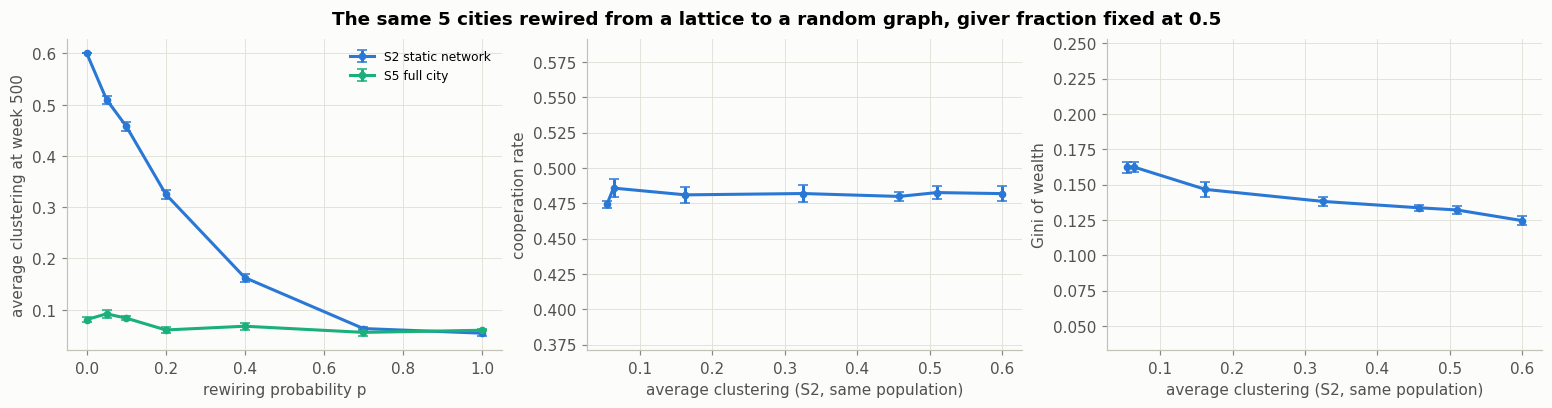

,lattice (p = 0),random (p = 1),paired change,se
metric,,,,
clustering,0.6000,0.0542,-0.5458,0.0056
coop_rate,0.4818,0.4743,-0.0075,0.0066
gini,0.1245,0.1623,0.0378,0.0038


In [15]:
# One population, one mean degree, one giver fraction: only the arrangement of ties changes.
REWIRE = [0.0, 0.05, 0.1, 0.2, 0.4, 0.7, 1.0]
WS_SCENARIOS = {f"{label}|{p}": (base, {"topology.name": "watts_strogatz",
                                        "topology.ws_rewire_prob": p})
                for label, base in [("S2 static network", "M1"), ("S5 full city", "M4")]
                for p in REWIRE}
ws = R.sweep(WS_SCENARIOS, [0.5], n_seeds=N_SEEDS, workers=WORKERS, **SETTINGS)
ws["stage"] = ws["scenario"].str.split("|").str[0]
ws["rewire"] = ws["scenario"].str.split("|").str[1].astype(float)
dial = R.cell_means(ws, ["clustering", "coop_rate", "gini"], by=("stage", "rewire"))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for stage_label, colour in zip(["S2 static network", "S5 full city"], [P.SERIES[0], P.SERIES[2]]):
    rows = dial[dial["stage"] == stage_label].sort_values("rewire")
    axes[0].errorbar(rows["rewire"], rows["clustering"], yerr=rows["clustering_se"],
                     color=colour, marker="o", markersize=4, capsize=3, label=stage_label)
axes[0].set(xlabel="rewiring probability p", ylabel="average clustering at week 500")
axes[0].legend(fontsize=8)

static = dial[dial["stage"] == "S2 static network"].sort_values("clustering")
# The y range is set to the size of the effect that partner choice produced (+0.110 cooperation),
# so that "flat" is read against something rather than against the width of the axis.
for ax, metric, label, span in [(axes[1], "coop_rate", "cooperation rate", 0.11),
                                (axes[2], "gini", "Gini of wealth", 0.11)]:
    ax.errorbar(static["clustering"], static[metric], yerr=static[f"{metric}_se"],
                color=P.SERIES[0], marker="o", markersize=4, capsize=3)
    centre = static[metric].mean()
    ax.set(xlabel="average clustering (S2, same population)", ylabel=label,
           ylim=(centre - span, centre + span))
fig.suptitle(f"The same {N_SEEDS} cities rewired from a lattice to a random graph, giver "
             "fraction fixed at 0.5", fontweight="bold")
P.save(fig, "lattice_to_random")
plt.show()

paired = ws[ws["stage"] == "S2 static network"].pivot_table(
    index="repeat", columns="rewire", values=["clustering", "coop_rate", "gini"])
pd.DataFrame([{"metric": m, "lattice (p = 0)": paired[m][0.0].mean(),
               "random (p = 1)": paired[m][1.0].mean(),
               "paired change": (paired[m][1.0] - paired[m][0.0]).mean(),
               "se": (paired[m][1.0] - paired[m][0.0]).sem()}
              for m in ["clustering", "coop_rate", "gini"]]).set_index("metric").round(4)

**Key findings:**

- **Breaking ties without replacing them splits the network:** in S4, clustering rises from 0.070
  to 0.105, the average distance between citizens rises from 2.70 to 2.95 steps, and the network
  breaks into 1.4 pieces on average. The average distance only counts citizens who can still reach
  each other, so a network that breaks apart can show a shorter distance; here it is longer anyway.
  In S5, where broken ties are replaced with friends of friends, clustering barely changes (0.070 to
  0.074), the distance stays at 2.70 and the network stays in one piece. In S6 the network ends in
  about 40 pieces, almost all of them single citizens with no ties.
- **Clustering has little effect on cooperation:** reducing clustering from 0.600 to 0.054, with the
  same citizens, the same number of ties and half givers, changes the cooperation rate by -0.0075
  (standard error 0.0066). That is not different from zero with 5 seeds. Its best estimate is about
  a fourteenth of the +0.109 that partner choice causes, and even the top of its 95% interval
  (about 0.02) is less than a fifth.
- **Inequality rises along the same range, but we cannot say why:** the Gini rises by 0.038
  (standard error 0.004), from 0.125 on the ring to 0.162 on the random network. This could mean
  clustering protects the poorest. But the Watts-Strogatz method also makes the number of ties less
  even: on the ring every citizen has exactly 6, on the random network some have more and some
  fewer. Tie capacity is fixed at the starting number, so this is itself unequal access. This test
  cannot separate the two explanations.
- **Takers have higher clustering than givers in S4** (right panel). This is probably a side effect
  of the measure, not takers forming groups: clustering divides by the number of pairs of
  acquaintances, and takers have fewer ties. We have not run a comparison that controls for the
  number of ties.

> **Insight 4:** in this model, how ties are arranged has little effect on cooperation, compared with
> who chooses to meet whom.
>
> **Why this happens in the model:** clustering in the literature helps cooperation because
> clustered cooperators earn more and are copied. Nobody here changes strategy, so clustering can
> only matter through who meets whom, and partner choice already decides that.
>
> **Model compared to expectations based on reality:** this does not contradict the evidence that
> clustering supports cooperation [8], [9], because the process behind that
> evidence is missing from our model. H2's reasoning should rest on attention and reputation, which
> the next section measures, rather than on clustering.

### Inequality When Nobody Is Cheated

A city where every citizen plays Tit-for-Tat, so nobody is ever cheated, turns out to be almost as
unequal as a mixed city. There are two possible reasons: some citizens get into frequent, rewarding
relationships early, or some get stuck in relationships where both sides punish each other.

The second cannot happen when everyone plays Tit-for-Tat. Tit-for-Tat cooperates first and then
copies, so two Tit-for-Tat players cooperate in every game. Every game pays `R = 3` to both, so

$$ \text{wealth}_i = 3 \times \text{games played}_i $$

exactly. In this city, inequality of wealth is only inequality in how many games each citizen
plays. So we can find what drives it by switching off the two parts of the choice rule one at a
time: past meetings ($\beta$) and reputation ($\gamma$).

**Purpose and layout:** To find where inequality comes from in a city where nobody is ever cheated, and how early the winners are decided. Left, Lorenz curves for three single cities. A Lorenz curve shows the share of all
wealth (vertical) held by the poorest share of citizens (horizontal); the diagonal is perfect
equality, and a curve further below it is more unequal. We draw single cities because averaging
Lorenz curves from different cities does not give a real distribution; the averaged Gini values are
in the table. Right: for the city where everyone plays TFT, how well the ranking of citizens by
games played at a given week matches the ranking at week 500 (1 means the order is already fixed).
The dashed line is how well each citizen's starting number of ties predicts the final ranking.

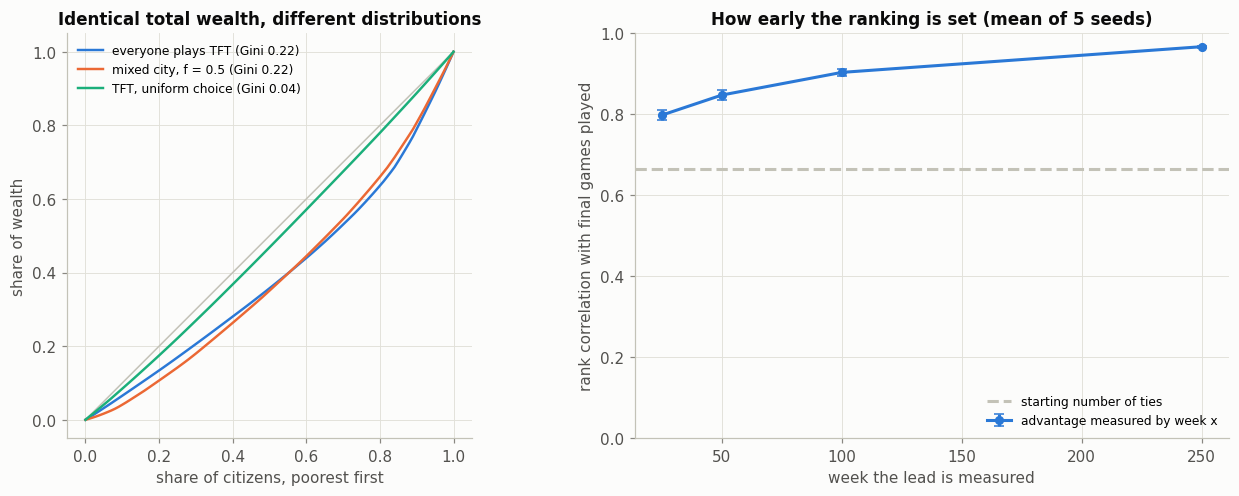

every move cooperative, so wealth is exactly three times games played: True
lock-in, mean of 5 seeds (se in brackets): week 25 0.80 (0.01), week 50 0.85 (0.01), week 100 0.90 (0.01), week 250 0.97 (0.00) | starting ties 0.66 (0.03)
TFT-only Gini 0.210 | mixed city Gini 0.226 (se 0.011, 5 seeds each)


,scenario,gini,mean_wealth,gini_se,mean_wealth_se
0,full: habit x status,0.2104,3000.0,0.0041,0.0
1,habit only,0.0524,3000.0,0.0005,0.0
2,neither: uniform,0.0494,3000.0,0.0038,0.0
3,status only,0.1324,3000.0,0.0039,0.0


In [16]:
CHOICE_VARIANTS = {
    "full: habit x status": ("M4", {}),
    "status only":          ("M4", {"encounter.weight_exponent": 0.0}),
    "habit only":           ("M4", {"encounter.popularity_exponent": 0.0}),
    "neither: uniform":     ("M4", {"encounter.weight_exponent": 0.0, "encounter.popularity_exponent": 0.0}),
}
ALL_TFT = {"population.giver_composition": {"tft": 1.0}}
tft_runs = R.sweep(CHOICE_VARIANTS, [1.0], n_seeds=N_SEEDS, workers=WORKERS, **{**SETTINGS, **ALL_TFT})
decomposition = R.cell_means(tft_runs, ["gini", "mean_wealth"], by=("scenario",))

# The mixed city on the same seeds, so the two Ginis compared in the text are the same kind of
# number: a mean over runs, not one city against an average.
mixed_reference = R.sweep({"mixed city, f = 0.5": ("M4", {})}, [0.5], n_seeds=N_SEEDS, workers=WORKERS, **SETTINGS)

curves, curve_ginis = {}, {}
for label, overrides in [("everyone plays TFT", {**ALL_TFT, "population.giver_fraction": 1.0}),
                         ("mixed city, f = 0.5", {"population.giver_fraction": 0.5}),
                         ("TFT, uniform choice", {**ALL_TFT, "population.giver_fraction": 1.0,
                                                  "encounter.weight_exponent": 0.0,
                                                  "encounter.popularity_exponent": 0.0})]:
    sim = Simulation(stage("M4", **{**SETTINGS, **overrides}), root_seed=R.DEFAULT_SEED,
                     repeat=0, instruments=("core",))
    sim.run()
    curves[label], curve_ginis[label] = metrics.lorenz(sim.state.wealth), metrics.gini(sim.state.wealth)

# Does an early lead survive? Rank citizens by games played at several points, against the end.
# Averaged over the same seeds as everything else, rather than read off one city.
MARKS = [25, 50, 100, 250]
lock_rows = []
for repeat in range(N_SEEDS):
    watch = Simulation(stage("M4", **{**SETTINGS, **ALL_TFT, "population.giver_fraction": 1.0}),
                       root_seed=R.DEFAULT_SEED, repeat=repeat, instruments=("core",))
    marks = {}
    for _ in range(SETTINGS["run.n_rounds"]):
        watch.run_round()
        if watch.state.t in MARKS:
            marks[watch.state.t] = watch.state.games_played.copy()
    final_games = watch.state.games_played
    lock_rows.append({**{week: metrics.spearman(marks[week], final_games) for week in MARKS},
                      "starting ties": metrics.spearman(watch.state.capacity, final_games),
                      "wealth is exactly 3x games": np.allclose(watch.state.wealth, 3.0 * final_games)})
lock = pd.DataFrame(lock_rows)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
P.lorenz_curves(axes[0], curves, ginis=curve_ginis)
axes[0].legend(fontsize=8, loc="upper left")
axes[0].set_title("Identical total wealth, different distributions")
axes[1].errorbar(MARKS, lock[MARKS].mean(), yerr=lock[MARKS].sem(), color=P.SERIES[0],
                 marker="o", capsize=3, label="advantage measured by week x")
axes[1].axhline(lock["starting ties"].mean(), color=P.AXIS, linestyle="--",
                label="starting number of ties")
axes[1].set(xlabel="week the lead is measured", ylabel="rank correlation with final games played",
            ylim=(0, 1), title=f"How early the ranking is set (mean of {N_SEEDS} seeds)")
axes[1].legend(fontsize=8, loc="lower right")
P.save(fig, "positional")
plt.show()

print(f"every move cooperative, so wealth is exactly three times games played: "
      f"{lock['wealth is exactly 3x games'].all()}")
print(f"lock-in, mean of {N_SEEDS} seeds (se in brackets): "
      + ", ".join(f"week {w} {lock[w].mean():.2f} ({lock[w].sem():.2f})" for w in MARKS)
      + f" | starting ties {lock['starting ties'].mean():.2f} ({lock['starting ties'].sem():.2f})")
print(f"TFT-only Gini {decomposition.set_index('scenario').loc['full: habit x status', 'gini']:.3f} "
      f"| mixed city Gini {mixed_reference['gini'].mean():.3f} "
      f"(se {mixed_reference['gini'].sem():.3f}, {N_SEEDS} seeds each)")
decomposition.round(4)

**Key findings:**

| Partner choice, everyone plays TFT | Gini | Wealth per person |
|---|---|---|
| Past meetings and reputation | 0.210 | 3,000 |
| Reputation only | 0.132 | 3,000 |
| Past meetings only | 0.052 | 3,000 |
| Neither: partners drawn with equal chance | 0.049 | 3,000 |

- **Total wealth is the same in all four:** the city plays the same number of games whatever the
  choice rule, and every game pays 3 to each side. Only who plays the games changes, and that alone
  moves the Gini from 0.049 to 0.210.
- **Reputation causes most of it:** removing reputation brings the Gini back to the equal-chance
  level (0.052 against 0.049, a difference smaller than either standard error). Removing past
  meetings leaves 0.132. Past meetings on their own add nothing measurable, but together with
  reputation they double its effect (0.161 above the equal-chance level, against 0.083 for
  reputation alone). This fits the rating rule: a citizen's rating includes the strength of its
  ties, and past meetings are what build that strength.
- **The ranking is set early:** the ranking of citizens by games played at week 25 already matches
  the ranking at week 500 with a correlation of 0.80, rising to 0.97 by week 250. The starting
  number of ties alone predicts it at 0.66. So citizens who are met often early stay met often.

A city of Tit-for-Tat players has a Gini of 0.210 and a mixed city 0.226, both averaged over the
same seeds. In both, most of the inequality comes from how often each citizen is met.

> **Insight 5:** without refusal, most inequality comes from differences in attention, not from
> cheating. A city where nobody is ever cheated is almost as unequal as a mixed one.
>
> **Why this happens in the model:** reputation includes how connected a citizen is, so citizens
> who are met often early get higher ratings, which gets them met more. Removing reputation from
> partner choice removes the inequality.
>
> **Model compared to expectations based on reality:** this kind of cumulative advantage has been
> observed. In an online music market with 14,341 participants, letting people see what others had
> chosen made success more unequal and less predictable, and quality only partly decided it
> [16]. The size of the effect here, though, comes from our rating rule, which multiplies
> cooperation by connectedness. A different rule could give more or less inequality.

### Letting Citizens Refuse (S6)

S6 adds rule 4 to the full city: once a partner has cheated you, you stop meeting them and the tie
between you breaks. In computer simulations of evolving strategies, a strategy that follows this "walk
away" rule can spread through a population of defectors from a smaller starting share than the
other strategies tested [17]. Here every citizen follows it,
givers and takers alike, and no rule mentions class. The figure compares the same cities with and
without it.

**Purpose and layout:** To see what refusal does to givers, to takers and to the city as a whole, and how quickly takers are cut off. The first three panels compare the same cities without refusal (S5, dashed) and
with it (S6, solid), against the giver fraction, at week 500: wealth per giver (blue) and per taker
(orange); wealth per person; and the Gini of wealth. The fourth panel shows S6 only, over time: the
share of takers with no ties, one line per giver fraction. We show this panel over time because S6
has not settled by week 500, so the end state alone would hide how quickly takers are cut off.

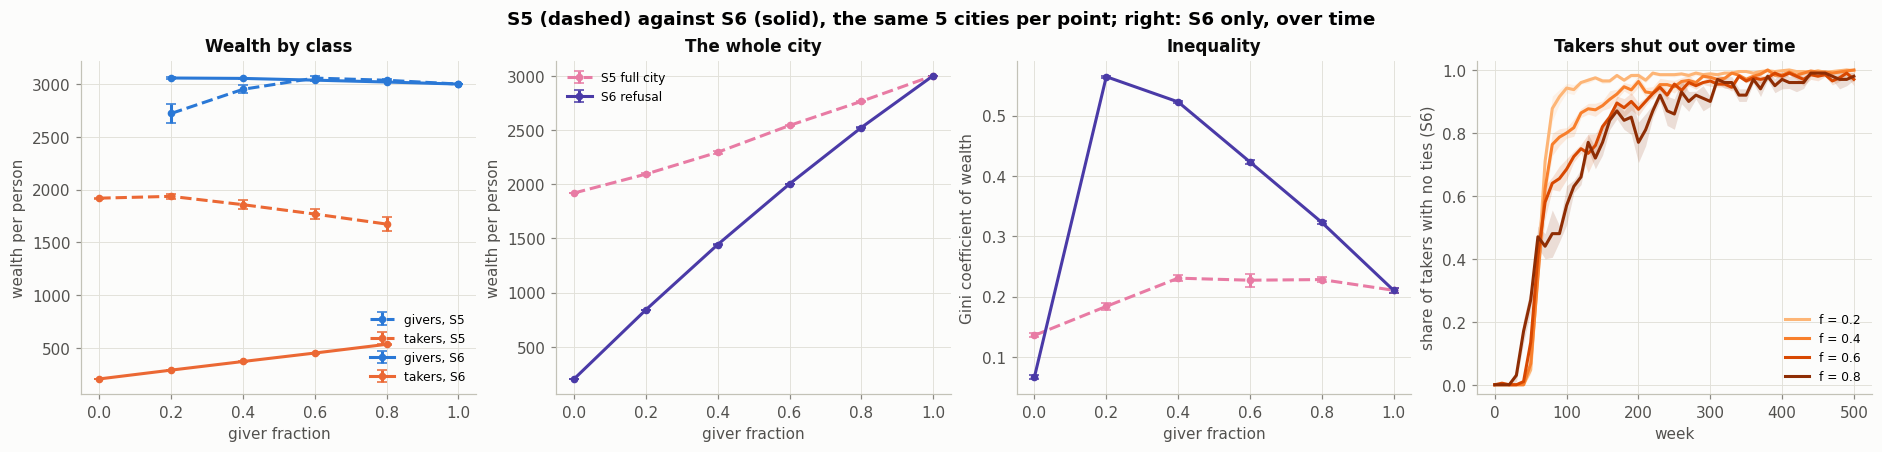

share of takers with no ties in S6, by week:
round            50    100   250   500
giver_fraction                        
0.2             0.05  0.94  0.98  1.00
0.4             0.07  0.80  0.95  1.00
0.6             0.14  0.68  0.95  0.97
0.8             0.27  0.57  0.86  0.98


gini             mean_wealth             \
scenario       S5 full city S6 refusal S5 full city S6 refusal   
giver_fraction                                                   
0.0                   0.136      0.067     1918.346    204.772   
0.2                   0.184      0.564     2092.656    842.060   
0.4                   0.230      0.523     2294.066   1443.368   
0.6                   0.227      0.423     2540.986   2002.224   
0.8                   0.228      0.323     2763.264   2521.914   
1.0                   0.210      0.210     3000.000   3000.000   

               taker_games_per_week            takers_cut_off             \
scenario               S5 full city S6 refusal   S5 full city S6 refusal   
giver_fraction                                                             
0.0                           2.000      0.234            0.0      1.000   
0.2                           1.760      0.243            0.0      0.997   
0.4                           1.509      0.252            0.0      1.000   
0.6                           1.326      0.261            0.0      0.970   
0.8                           1.256      0.272            0.0      0.980   
1.0                             NaN        NaN            NaN        NaN   

               wealth_giver            wealth_taker             
scenario       S5 full city S6 refusal S5 full city S6 refusal  
giver_fraction                                                  
0.0                     NaN        NaN     1918.346    204.772  
0.2                2721.430   3057.330     1935.462    288.242  
0.4                2950.365   3053.540     1856.533    369.920  
0.6                3056.590   3036.983     1767.580    450.085  
0.8                3035.950   3019.170     1672.520    532.890  
1.0                3000.000   3000.000          NaN        NaN

In [17]:
pair = runs[runs["scenario"].isin(["S5 full city", "S6 refusal"])].copy()
takers = (1 - pair["giver_fraction"]) * SETTINGS["population.n_agents"]
pair["takers_cut_off"] = np.where(takers > 0, pair["isolated_taker"] / takers.where(takers > 0, 1), np.nan)
pair["taker_games_per_week"] = pair["games_taker"] / SETTINGS["run.n_rounds"]
refuse = R.cell_means(pair, ["wealth_giver", "wealth_taker", "mean_wealth", "gini", "takers_cut_off",
                             "taker_games_per_week"])
STYLE = {"S5 full city": "--", "S6 refusal": "-"}

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for name in ["S5 full city", "S6 refusal"]:
    rows = refuse[refuse["scenario"] == name]
    for cls in ("giver", "taker"):
        axes[0].errorbar(rows["giver_fraction"], rows[f"wealth_{cls}"], yerr=rows[f"wealth_{cls}_se"],
                         color=P.CLASS_COLOURS[cls], linestyle=STYLE[name], marker="o", markersize=4,
                         capsize=3, label=f"{cls}s, {name.split()[0]}")
    for ax, metric in zip(axes[1:3], ["mean_wealth", "gini"]):
        ax.errorbar(rows["giver_fraction"], rows[metric], yerr=rows[f"{metric}_se"], color=colours[name],
                    linestyle=STYLE[name], marker="o", markersize=4, capsize=3, label=name)
axes[0].set(xlabel="giver fraction", ylabel="wealth per person", title="Wealth by class")
axes[1].set(xlabel="giver fraction", ylabel="wealth per person", title="The whole city")
axes[2].set(xlabel="giver fraction", ylabel="Gini coefficient of wealth", title="Inequality")
# S6 has not settled by week 500, so the last panel follows the shut-out over time rather than at the end.
history = sweep.structure[(sweep.structure["scenario"] == "S6 refusal")
                         & sweep.structure["giver_fraction"].between(0.15, 0.85)].copy()
history["takers_cut_off"] = history["isolated_taker"] / ((1 - history["giver_fraction"]) * SETTINGS["population.n_agents"])
shut = R.cell_means(history, ["takers_cut_off"], by=("giver_fraction", "round"))
shades = P.ramp(sorted(shut["giver_fraction"].unique()), cmap="Oranges")
for f, colour in shades.items():
    rows = shut[np.isclose(shut["giver_fraction"], f)].sort_values("round")
    P.band(axes[3], rows["round"], rows["takers_cut_off"], rows["takers_cut_off"] - rows["takers_cut_off_se"],
           rows["takers_cut_off"] + rows["takers_cut_off_se"], colour, label=f"f = {f:g}")
axes[3].set(xlabel="week", ylabel="share of takers with no ties (S6)", title="Takers shut out over time",
            ylim=(-0.03, 1.03))
axes[3].legend(fontsize=8, loc="lower right")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
fig.suptitle(f"S5 (dashed) against S6 (solid), the same {N_SEEDS} cities per point; right: S6 only, over time",
             fontweight="bold")
P.save(fig, "refusal")
plt.show()

print("share of takers with no ties in S6, by week:")
print(shut[shut["round"].isin([50, 100, 250, 500])].pivot_table(index="giver_fraction", columns="round",
                                                                 values="takers_cut_off").round(2).to_string())
refuse.pivot_table(index="giver_fraction", columns="scenario",
                   values=["wealth_giver", "wealth_taker", "mean_wealth", "gini", "takers_cut_off",
                           "taker_games_per_week"]).round(3)

**Key findings:**

- **Givers do as well whatever the mix:** under refusal a giver ends with about 3,000 at every mix
  (3,057 at `f = 0.2`, against 2,721 without refusal).
- **Takers are cut off:** in mixed cities, 97% to 100% of takers have no ties at week 500. The right-hand panel shows how quickly this happens. At 20% givers, 5% of takers have no ties by week 50, 94% by week 100 and 98% by week 250. At 80% givers, 27% have no ties by week 50, but only 57% by week 100 and 86% by week 250. We have not looked into why the timing differs between mixes.
  A taker plays about a quarter of a game a week (0.24 to 0.27), against 1.3 to 1.8 without
  refusal, and ends with 290 to 530 instead of 1,670 to 1,940.
- **The city is poorer where takers are common:** wealth per person at `f = 0.2` falls from 2,093 to
  842; at `f = 0.8` it falls only from 2,763 to 2,522. A taker that nobody meets creates no wealth
  at all, while a taker that cheats a giver still creates 5 units per game between them.
- **Inequality follows the mix:** the Gini is 0.564 at `f = 0.2` and falls to 0.323 at `f = 0.8`,
  against 0.18 to 0.23 without refusal. In a city with few givers, those givers stay rich while most
  citizens are cut off.

> **Insight 6:** permanent refusal protects givers and cuts takers off. Cities with many takers
> become much poorer and much more unequal.
>
> **Why this happens in the model:** every taker defects at some point, so every giver it meets
> eventually refuses it. Takers also defect on each other, so they cannot keep meeting each other
> either. A taker that nobody meets plays no games and earns nothing more.
>
> **Model compared to expectations based on reality:** the protection matches evidence from people.
> In experiments, people cut ties with those who defect [12], and groups that exclude selfish
> members suffer less from them [18]. The size of the cost is probably exaggerated here.
> In that experiment, excluded members went on to cooperate as much as everyone else
> [18]; our takers can never change, so their exclusion is permanent. And in our model
> wealth comes only from games, so an excluded citizen produces nothing, which is not true of real
> people.

In [18]:
# Does a giver who starts surrounded by takers stay poorer? Each giver's share of giver
# neighbours at week 0, against that giver's wealth at week 500, in cities where givers are scarce.
def start_and_finish(task):
    base, repeat = task
    sim = Simulation(stage(base, **{**SETTINGS, "population.giver_fraction": 0.2}),
                     root_seed=R.DEFAULT_SEED, repeat=repeat, instruments=("core",))
    start, giver = sim.state.adjacency.copy(), sim.state.giver
    share = (start & giver[None, :]).sum(axis=1) / np.maximum(start.sum(axis=1), 1)
    sim.run()
    w = sim.state.wealth
    alone = giver & (share == 0)
    return {"scenario": {"M4": "S5 full city", "M5": "S6 refusal"}[base], "repeat": repeat,
            "rank correlation, start vs final wealth": metrics.spearman(share[giver], w[giver]),
            "givers with no giver neighbours": int(alone.sum()),
            "their wealth": w[alone].mean() if alone.any() else np.nan,
            "all givers' wealth": w[giver].mean()}


surround = pd.DataFrame(R.parallel_map(start_and_finish, [(b, r) for b in ("M4", "M5") for r in range(N_SEEDS)],
                                     workers=WORKERS))
surround["their shortfall"] = 1 - surround["their wealth"] / surround["all givers' wealth"]
summary = surround.groupby("scenario").agg(["mean", "sem"]).drop(columns="repeat")
summary.round(3)

rank correlation, start vs final wealth         \
                                                mean    sem   
scenario                                                      
S5 full city                                   0.363  0.062   
S6 refusal                                     0.235  0.077   

             givers with no giver neighbours        their wealth           \
                                        mean    sem         mean      sem   
scenario                                                                    
S5 full city                             4.8  1.068     1834.425  167.603   
S6 refusal                               4.8  1.068     2544.803  233.847   

             all givers' wealth         their shortfall         
                           mean     sem            mean    sem  
scenario                                                        
S5 full city            2721.43  87.389           0.317  0.080  
S6 refusal              3057.33   6.989           0.168  0.075

**Key findings (a giver surrounded by takers):** In cities with 20% givers, about 5 givers per city start with no
giver among their neighbours. Without refusal they end 32% poorer than the average giver (1,834
against 2,721), and the share of givers among a giver's starting neighbours is correlated with its
final wealth (0.36). With refusal the gap is smaller (17%, correlation 0.24). With 5 seeds, though,
the two gaps overlap within their standard errors (0.08 each), so we cannot say whether refusal
helps these givers. In both cases, who a giver starts next to appears to matter. This is consistent
with the real finding that who a person's friends are is linked to their economic mobility
[2], but our result is too uncertain to treat as a finding.

### How Long a Refusal Lasts

In S6 a refusal is permanent. Here a refusal ends `W` weeks after the pair's last game, with `W`
from 1 to 208 weeks. "Never" is S5 (no refusal) and "forever" is S6. We use two mixes: 20% givers,
where takers are the majority, and 50%. The `idle` column in the table is the average number of
citizens per week, over the last 100 weeks, who had nobody within reach willing to meet them.

**Purpose and layout:** To see how the effects of refusal depend on how long a refusal lasts. The horizontal axis is how long a refusal lasts, from never (S5) to forever (S6);
the steps are not evenly spaced. Light lines are cities with 20% givers and dark lines 50%. From
left, all at week 500: the Gini of wealth; the share of inequality between givers and takers (0:
none, 1: all); wealth per giver (blue) and per taker (orange); and wealth per person. We show the end
of the run because the question is where each setting leads.

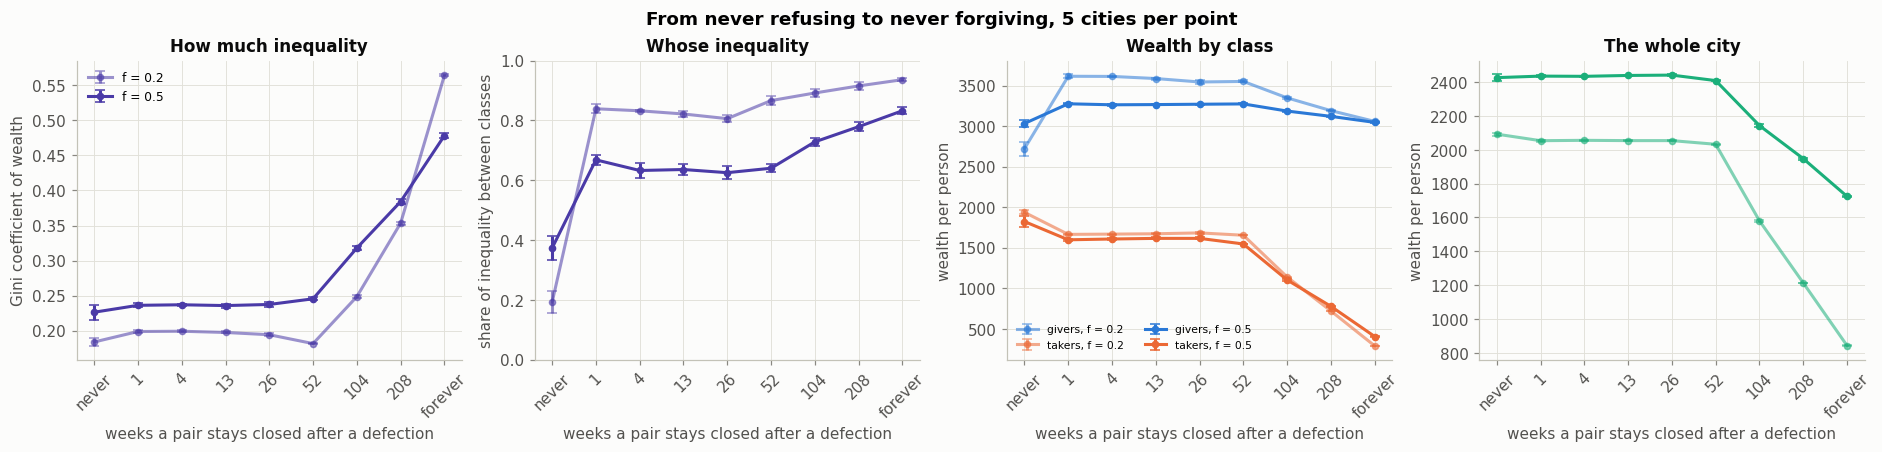

gini        between_share        wealth_giver            \
giver_fraction    0.2    0.5           0.2    0.5          0.2       0.5   
scenario                                                                   
never           0.184  0.226         0.192  0.373      2721.43  3031.408   
1               0.199  0.236         0.839  0.668      3614.14  3274.712   
4               0.199  0.237         0.832  0.632      3612.22  3262.196   
13              0.197  0.236         0.821  0.636      3585.99  3264.884   
26              0.194  0.237         0.806  0.625      3543.55  3269.132   
52              0.181  0.245         0.866  0.640      3550.29  3272.980   
104             0.248  0.318         0.891  0.728      3347.46  3184.932   
208             0.353  0.384         0.915  0.779      3190.24  3119.484   
forever         0.564  0.478         0.936  0.832      3057.33  3045.084   

               wealth_taker           mean_wealth              idle          
giver_fraction          0.2       0.5         0.2       0.5     0.2     0.5  
scenario                                                                     
never              1935.462  1822.108    2092.656  2426.758   0.000   0.000  
1                  1663.805  1596.880    2053.872  2435.796   0.002   0.000  
4                  1666.985  1606.772    2056.032  2434.484   0.004   0.000  
13                 1671.367  1614.428    2054.292  2439.656   0.004   0.006  
26                 1682.048  1614.372    2054.348  2441.752   0.004   0.004  
52                 1653.222  1545.548    2032.636  2409.264   0.990   2.464  
104                1137.908  1101.300    1579.818  2143.116  27.114  17.908  
208                 718.645   776.064    1212.964  1947.774  30.048  22.930  
forever             288.242   403.912     842.060  1724.498  79.674  49.442

In [19]:
# A pair that has had a defection stays closed for this many weeks after their last game.
MEMORY = [1, 4, 13, 26, 52, 104, 208]
GRUDGE = {"never": ("M4", {}),
          **{str(w): ("M5", {"encounter.refusal_memory": w}) for w in MEMORY},
          "forever": ("M5", {})}
grudge = R.sweep(GRUDGE, [0.2, 0.5], n_seeds=N_SEEDS, workers=WORKERS, **SETTINGS)
grudge["between_share"] = grudge["theil_between"] / grudge["theil"]
dial_means = R.cell_means(grudge, ["gini", "between_share", "wealth_giver", "wealth_taker", "mean_wealth", "idle"])
order = list(GRUDGE)
dial_means["position"] = dial_means["scenario"].map({name: k for k, name in enumerate(order)})

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
shade = {0.2: 0.55, 0.5: 1.0}
for f in (0.2, 0.5):
    rows = dial_means[np.isclose(dial_means["giver_fraction"], f)].sort_values("position")
    x = rows["position"]
    for ax, metric, colour in [(axes[0], "gini", P.SERIES[6]), (axes[1], "between_share", P.SERIES[6]),
                               (axes[3], "mean_wealth", P.SERIES[2])]:
        ax.errorbar(x, rows[metric], yerr=rows[f"{metric}_se"], color=colour, alpha=shade[f],
                    marker="o", markersize=4, capsize=3, label=f"f = {f}")
    for cls in ("giver", "taker"):
        axes[2].errorbar(x, rows[f"wealth_{cls}"], yerr=rows[f"wealth_{cls}_se"], color=P.CLASS_COLOURS[cls],
                         alpha=shade[f], marker="o", markersize=4, capsize=3, label=f"{cls}s, f = {f}")
for ax, label, title in [(axes[0], "Gini coefficient of wealth", "How much inequality"),
                         (axes[1], "share of inequality between classes", "Whose inequality"),
                         (axes[2], "wealth per person", "Wealth by class"),
                         (axes[3], "wealth per person", "The whole city")]:
    ax.set_xticks(range(len(order)), order, rotation=45)
    ax.set(xlabel="weeks a pair stays closed after a defection", ylabel=label, title=title)
axes[1].set_ylim(0, 1)
axes[0].legend(fontsize=8)
axes[2].legend(fontsize=7, ncol=2)
fig.suptitle(f"From never refusing to never forgiving, {N_SEEDS} cities per point", fontweight="bold")
P.save(fig, "forgiveness")
plt.show()

dial_means.pivot_table(index="scenario", columns="giver_fraction",
                       values=["gini", "between_share", "wealth_giver", "wealth_taker", "mean_wealth", "idle"],
                       sort=False).loc[order].round(3)

**Key findings:**

- **A short refusal changes who is poor, not how much inequality there is:** refusing a cheat for
  one week barely changes the Gini (0.184 to 0.199 at `f = 0.2`) or wealth per person (2,093 to
  2,054). But the share of inequality between givers and takers rises from 0.19 to 0.84. Givers
  gain (2,721 to 3,614) and takers lose (1,935 to 1,664).
- **Between 1 and 52 weeks:** little changes.
- **Longer refusals cut takers off and the city loses wealth:** at `f = 0.5`, wealth per person
  falls from 2,409 at 52 weeks to 2,143 at 104 weeks, 1,948 at 208 and 1,724 when refusal is
  permanent, and the Gini rises from 0.245 to 0.478. The `idle` column shows when takers start to
  run out of partners: almost nobody is left without a partner at 26 weeks, about 2 citizens a week
  are at 52 weeks, and about 18 are at 104 weeks.

> **Insight 7:** a short refusal moves the bottom of the wealth distribution from givers to takers
> at almost no cost to the city. A long refusal cuts takers off, and the city loses the wealth
> their games would have created.
>
> **Why this happens in the model:** while refusals end quickly, a taker always has someone willing
> to meet it, so it keeps playing, but it cannot cheat the same giver week after week. Once refusals
> last long enough, a taker runs out of citizens within reach who will still meet it, and stops
> playing.
>
> **Model compared to expectations based on reality:** it seems reasonable that forgiveness lets a
> cheat keep finding partners. The point at which the city starts to lose wealth (between 52 and 104
> weeks) is not a real-world duration. It depends on the city having 100 citizens, on how far
> citizens can reach and on how often they meet, and would change with any of these.

### What the Gini Coefficient Does and Does Not Show

Without refusal, the Gini of wealth is between about 0.16 and 0.25 in almost every city with a
network, whatever the mix, and whether or not anyone is cheated. We ask two questions about this
number: what produces it, and whose inequality is it? To answer the second, we use the Theil index,
another measure of inequality, which, unlike the Gini, splits exactly into a part within each class
and a part between the classes [19].

**Purpose and layout:** To see what the Gini coefficient of wealth reflects, and how much of the inequality lies between givers and takers. Left, one dot per city, coloured by scenario: the Gini of games played (horizontal)
against the Gini of wealth (vertical), at week 500. On the diagonal, wealth is exactly as unequal as
the number of games played. S1 is left out because every citizen there plays about two games a
week, so games played are almost equal. Centre: the Gini of wealth against the giver fraction.
Right: the share of that inequality between givers and takers, from the Theil index. The centre and
right panels show S2, S4, S5 and S6; S3 is identical to S2, and the table gives the other
scenarios.

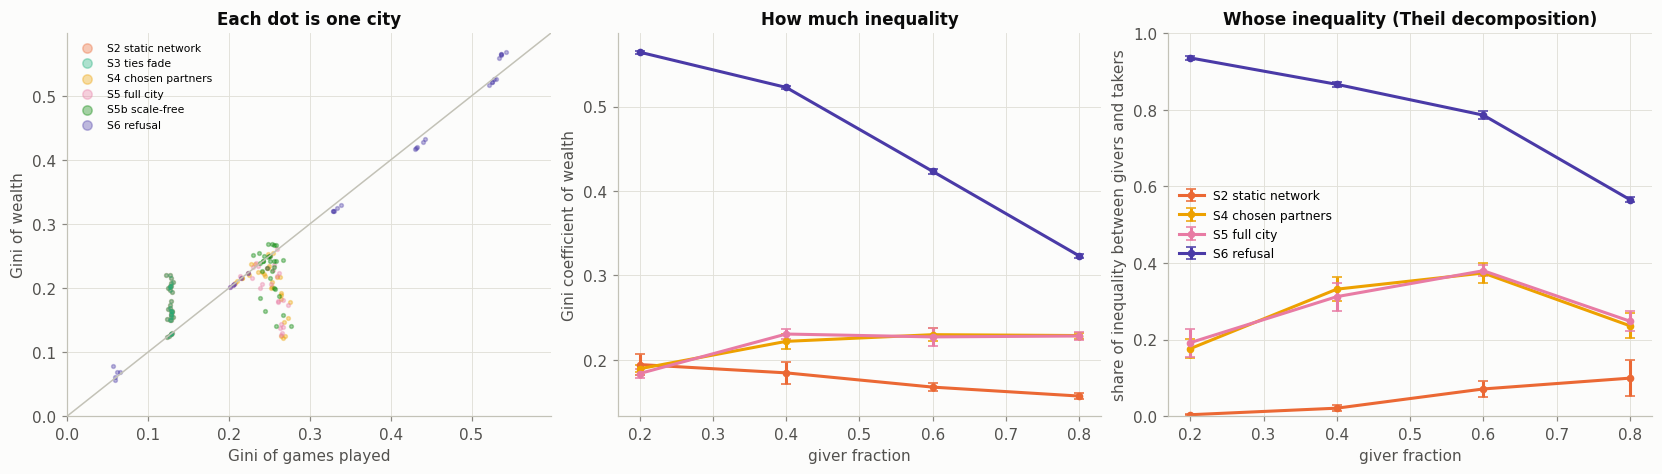

rank correlation of Gini of wealth with Gini of games played, networked cities: 0.52 (180 cities)


between_share                                 \
scenario       S1 well-mixed S2 static network S3 ties fade   
giver_fraction                                                
0.2                    0.102             0.004        0.004   
0.4                    0.008             0.021        0.021   
0.6                    0.245             0.071        0.071   
0.8                    0.634             0.099        0.099   

                                                                          \
scenario       S4 chosen partners S5 full city S5b scale-free S6 refusal   
giver_fraction                                                             
0.2                         0.176        0.192          0.102      0.936   
0.4                         0.332        0.312          0.187      0.867   
0.6                         0.374        0.380          0.318      0.786   
0.8                         0.236        0.248          0.220      0.566   

                        gini                                 ...               \
scenario       S1 well-mixed S2 static network S3 ties fade  ... S5 full city   
giver_fraction                                               ...                
0.2                    0.081             0.194        0.194  ...        0.184   
0.4                    0.050             0.184        0.184  ...        0.230   
0.6                    0.036             0.168        0.168  ...        0.227   
0.8                    0.031             0.157        0.157  ...        0.228   

                                          gini_surplus                    \
scenario       S5b scale-free S6 refusal S1 well-mixed S2 static network   
giver_fraction                                                             
0.2                     0.213      0.564         0.175             0.364   
0.4                     0.241      0.523         0.095             0.304   
0.6                     0.248      0.423         0.061             0.243   
0.8                     0.251      0.323         0.046             0.197   

                                                                            \
scenario       S3 ties fade S4 chosen partners S5 full city S5b scale-free   
giver_fraction                                                               
0.2                   0.364              0.254        0.248          0.299   
0.4                   0.304              0.264        0.271          0.291   
0.6                   0.243              0.243        0.236          0.264   
0.8                   0.197              0.234        0.235          0.256   

                           
scenario       S6 refusal  
giver_fraction             
0.2                 0.586  
0.4                 0.521  
0.6                 0.417  
0.8                 0.318  

[4 rows x 21 columns]

In [20]:
# With every payoff between S = 0 and T = 5, wealth is roughly (payoff per game) x (games played),
# so the Gini of wealth should track the Gini of games played.
networked = runs[runs["scenario"] != "S1 well-mixed"]
mixed_runs = runs[runs["giver_fraction"].between(0.15, 0.85)].assign(
    between_share=lambda d: d["theil_between"] / d["theil"])
split = R.cell_means(mixed_runs, ["gini", "between_share", "gini_surplus"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for name in [s for s in SCENARIOS if s != "S1 well-mixed"]:
    rows = networked[networked["scenario"] == name]
    axes[0].scatter(rows["gini_games"], rows["gini"], s=6, alpha=0.35, color=colours[name], label=name)
top = max(networked["gini"].max(), networked["gini_games"].max()) * 1.05
axes[0].plot([0, top], [0, top], color=P.AXIS, linewidth=1)
axes[0].set(xlabel="Gini of games played", ylabel="Gini of wealth", xlim=(0, top), ylim=(0, top),
            title="Each dot is one city")
axes[0].legend(fontsize=7, markerscale=2.5, loc="upper left")
for name in ["S2 static network", "S4 chosen partners", "S5 full city", "S6 refusal"]:
    rows = split[split["scenario"] == name]
    for ax, metric in zip(axes[1:], ["gini", "between_share"]):
        ax.errorbar(rows["giver_fraction"], rows[metric], yerr=rows[f"{metric}_se"], color=colours[name],
                    marker="o", markersize=4, capsize=3, label=name)
axes[1].set(xlabel="giver fraction", ylabel="Gini coefficient of wealth", title="How much inequality")
axes[2].set(xlabel="giver fraction", ylabel="share of inequality between givers and takers",
            ylim=(0, 1), title="Whose inequality (Theil decomposition)")
axes[2].legend(fontsize=8)
P.save(fig, "gini_decomposition")
plt.show()

print(f"rank correlation of Gini of wealth with Gini of games played, networked cities: "
      f"{metrics.spearman(networked['gini'], networked['gini_games']):.2f} ({len(networked)} cities)")
split.pivot_table(index="giver_fraction", columns="scenario",
                  values=["gini", "gini_surplus", "between_share"]).round(3)

**Key findings:**

- **The Gini of wealth follows the Gini of games played, but not exactly:** across 180 cities with
  a network, the two are correlated at 0.52. In S2 and S3, where partners are drawn with equal
  chance, citizens play a similar number of games (Gini of games about 0.13), and most dots sit
  above the diagonal: the inequality comes from what each game pays. In S4 and S5, the number of
  games is less equal (about 0.25), and most dots sit below the diagonal. The takers, who are met
  least, earn the most per game, which partly offsets the inequality in games. In S6 the dots sit on
  the diagonal: a taker that is cut off neither plays nor earns.
- **Similar Gini values hide different cities:** in S2 almost none of the inequality is between
  givers and takers (0.004 to 0.099). In S5 a fifth to two fifths is (0.19 to 0.38). With refusal
  most of it is (0.57 to 0.94).
- **Subtracting the mutual-defection payoff changes the scores, not the cities:** if every game is
  charged `P = 1`, being cheated costs wealth (payoffs 4, 2, 0, -1). This raises the Gini most where
  givers cannot avoid takers: in S2 and S3 at `f = 0.2` it nearly doubles (0.194 to 0.364) and
  becomes higher than S5's (0.248). Under refusal, where almost all remaining games are cooperative,
  it barely moves (0.564 to 0.586, and slightly lower at `f >= 0.6`). No citizen's choices depend on
  its wealth, so this only changes how the outcome is measured.

> **Insight 8:** cities with almost the same Gini can have their inequality almost entirely within
> each class or almost entirely between the classes. The Gini alone does not show which.
>
> **Why this happens:** the Gini is one number for the whole population and does not use the
> classes at all. The Theil index can be split into parts within and between groups, so it can show
> who the poor are.
>
> **Model compared to expectations based on reality:** this is a property of the measures, not of
> our model, so it applies to real populations too [19].

### A Taker That Cooperates Most of the Time (Joss)

AllD never cooperates, and Random cooperates half the time, so both quickly show what they are.
Joss, named after an entry in Axelrod's first tournament [20], plays Tit-for-Tat but
defects without being provoked in one game in ten, so most of its moves are cooperative. Here the
takers are split equally between AllD, Random and Joss, in cities with half givers, with and without
refusal.

**What the rules predict under refusal:** a giver never defects first, so a pair of a giver and a
taker stops meeting at the taker's first defection. Before that, every game pays the taker
`R = 3`, and the defection pays `T = 5`.

| Taker | Chance of defecting in a game with a giver | Expected games with a giver before it defects | Expected wealth from that giver before being refused |
|---|---|---|---|
| AllD | 1 | 1 | 5 |
| Random | 0.5 | 2 | 3 + 5 = 8 |
| Joss | 0.1 | 10 | 9 x 3 + 5 = 32 |

So under refusal we expect Joss to earn several times more than AllD and Random, and to stay
connected longer.

**Purpose and layout:** To compare how each strategy fares with and without refusal when one kind of taker cooperates most of the time. One pair of bars per strategy, with givers left of the vertical line and takers
right of it. Hatched bars are S5 and plain bars S6. From left, all at week 500: wealth; popularity
rating, which is all other citizens can see; and the share of each strategy with no ties. We run one
mix, half givers, to keep the number of runs small.

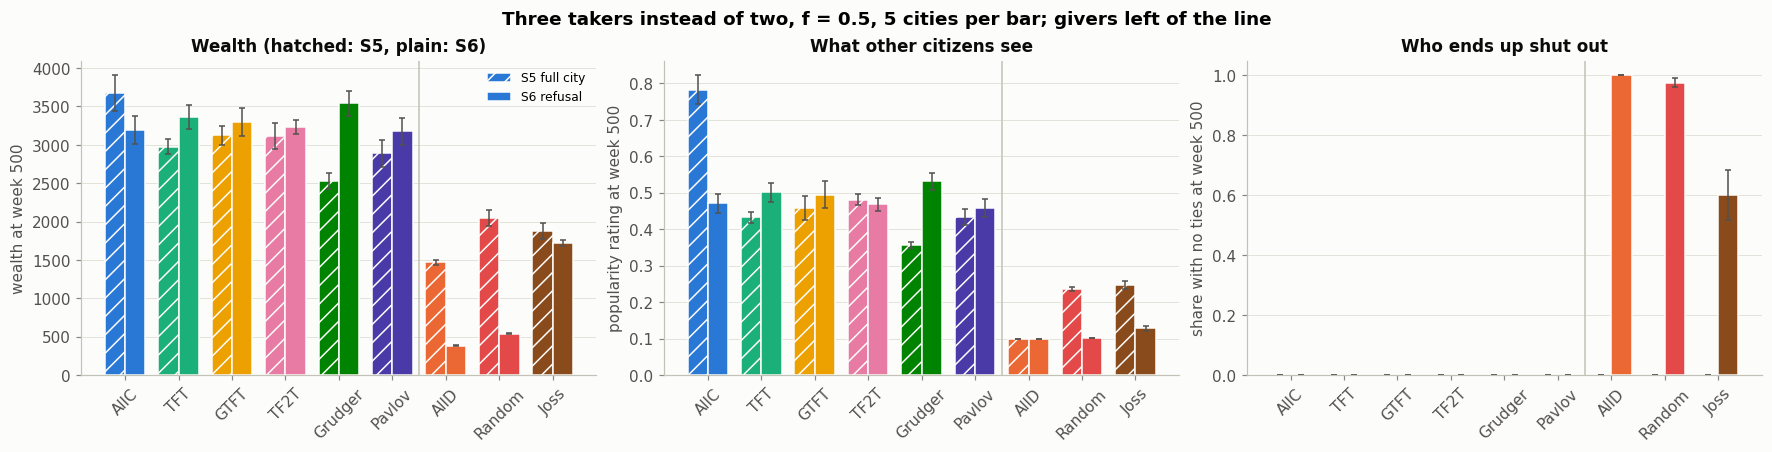

,S5 full city,S6 refusal
wealth AllD,1466.941,382.553
wealth Random,2049.294,537.824
wealth Joss,1876.050,1719.562
games AllD,598.376,98.365
games Random,801.435,162.294
games Joss,834.450,578.225
rating AllD,0.100,0.100
rating Random,0.235,0.100
rating Joss,0.247,0.128
isolated AllD,0.000,1.000


In [21]:
# A third kind of taker, mixed in equally with AllD and Random, at f = 0.5.
THREE_TAKERS = {"population.taker_composition": {"alld": 1.0, "random": 1.0, "joss": 1.0}}
JOSS_SCENARIOS = {"S5 full city": ("M4", THREE_TAKERS), "S6 refusal": ("M5", THREE_TAKERS)}
joss = R.sweep(JOSS_SCENARIOS, [0.5], n_seeds=N_SEEDS, instruments=("core", "snapshot"),
                workers=WORKERS, **SETTINGS)
KEYS = ["allc", "tft", "gtft", "tf2t", "grudger", "pavlov", "alld", "random", "joss"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
width = 0.38
x = np.arange(len(KEYS))
for k, (name, hatch) in enumerate([("S5 full city", "//"), ("S6 refusal", None)]):
    rows = joss[joss["scenario"] == name]
    for ax, measure in zip(axes, ["wealth", "rating", "isolated"]):
        values = [rows[f"{measure}_{key}"].mean() for key in KEYS]
        errors = [rows[f"{measure}_{key}"].sem() for key in KEYS]
        ax.bar(x + (k - 0.5) * width, values, width, yerr=errors, capsize=2, hatch=hatch,
               color=[P.STRATEGY_COLOURS[key] for key in KEYS], edgecolor=P.SURFACE, label=name,
               error_kw={"ecolor": P.INK_2, "elinewidth": 1})
for ax, label in zip(axes, ["wealth at week 500", "popularity rating at week 500",
                            "share with no ties at week 500"]):
    ax.set_xticks(x, [P.STRATEGY_LABELS[key] for key in KEYS], rotation=45)
    ax.set_ylabel(label)
    ax.axvline(5.5, color=P.AXIS, linewidth=1)
    ax.grid(axis="x", visible=False)
axes[0].legend(fontsize=8, loc="upper right")
axes[0].set_title("Wealth (hatched: S5, plain: S6)")
axes[1].set_title("What other citizens see")
axes[2].set_title("Who ends up shut out")
fig.suptitle(f"Three takers instead of two, f = 0.5, {N_SEEDS} cities per bar; givers left of the line",
             fontweight="bold")
P.save(fig, "joss")
plt.show()

pd.DataFrame({name: {f"{measure} {P.STRATEGY_LABELS[key]}": joss[joss["scenario"] == name][f"{measure}_{key}"].mean()
                     for measure in ["wealth", "games", "rating", "isolated"] for key in ["alld", "random", "joss"]}
              for name in JOSS_SCENARIOS}).round(3)

**Key findings:**

- **Under refusal, the result matches the prediction in direction and roughly in size:** AllD ends
  with 383, Random with 538 and Joss with 1,720. Compared with AllD, Joss earns 4.5 times as much
  (predicted 6.4) and Random 1.4 times (predicted 1.6). Joss plays 578 games, against 98 for AllD
  and 162 for Random, and 40% of Joss citizens still have ties at week 500, against almost none of
  the others. Joss's advantage is smaller than predicted. Possible reasons are that Joss also meets
  other takers, whose pairs close quickly, and that 500 weeks is not long enough to work through
  every giver it can reach. We have not tested which.
- **Without refusal, Joss earns less than Random** (1,876 against 2,049; AllD 1,467). The rules
  suggest a reason: after Joss defects, a TFT partner defects back, Joss copies that, and the pair
  can keep defecting at each other; with a Grudger partner, the pair defects for good. Random does
  not copy its partner, so its defections do not start these runs. We have not measured the runs
  directly.
- **Among givers, Grudger and TFT gain most from refusal** (left panel). Without refusal, a
  defection locks Grudger into defecting against that partner for good, and TFT into trading
  defections; with refusal the pair simply stops meeting. AllC is the only giver strategy whose
  wealth falls with refusal. Without refusal it has the highest rating (0.78), probably because
  takers keep choosing it, and those meetings stop once takers are refused.

> **Insight 9:** refusal based only on your own experience works poorly against a taker that
> cooperates most of the time. Joss loses about a tenth of its wealth to refusal, while AllD and
> Random lose about three quarters.
>
> **Why this happens in the model:** a citizen refuses only after being cheated, and Joss cooperates
> for about ten games with each new partner before it cheats, so it collects about four times as
> much from each partner as Random does (32 against 8).
>
> **Model compared to expectations based on reality:** in real groups, people also share what they
> know about others. In experiments, people used gossip to avoid partners who had behaved selfishly
> with others [18], which would stop a Joss before it cheats each new partner. Our model
> has a reputation-based refusal setting (`encounter.refusal = "reputation"`), but we have not
> studied it.

### One City Over Time, With and Without Refusal

The sections above average many cities. Here we follow one city of 60 citizens with half givers for
300 weeks, with and without refusal, from the same starting network and seed. A small city is used
so that individual citizens can be seen, and 300 weeks because most of the change happens by then.
Blue citizens are givers and orange are takers; the size of a citizen is its wealth, and the width
of a line is the strength of the tie. A citizen with no ties is drawn on the outer ring. The four
still frames are for print; the animation follows.

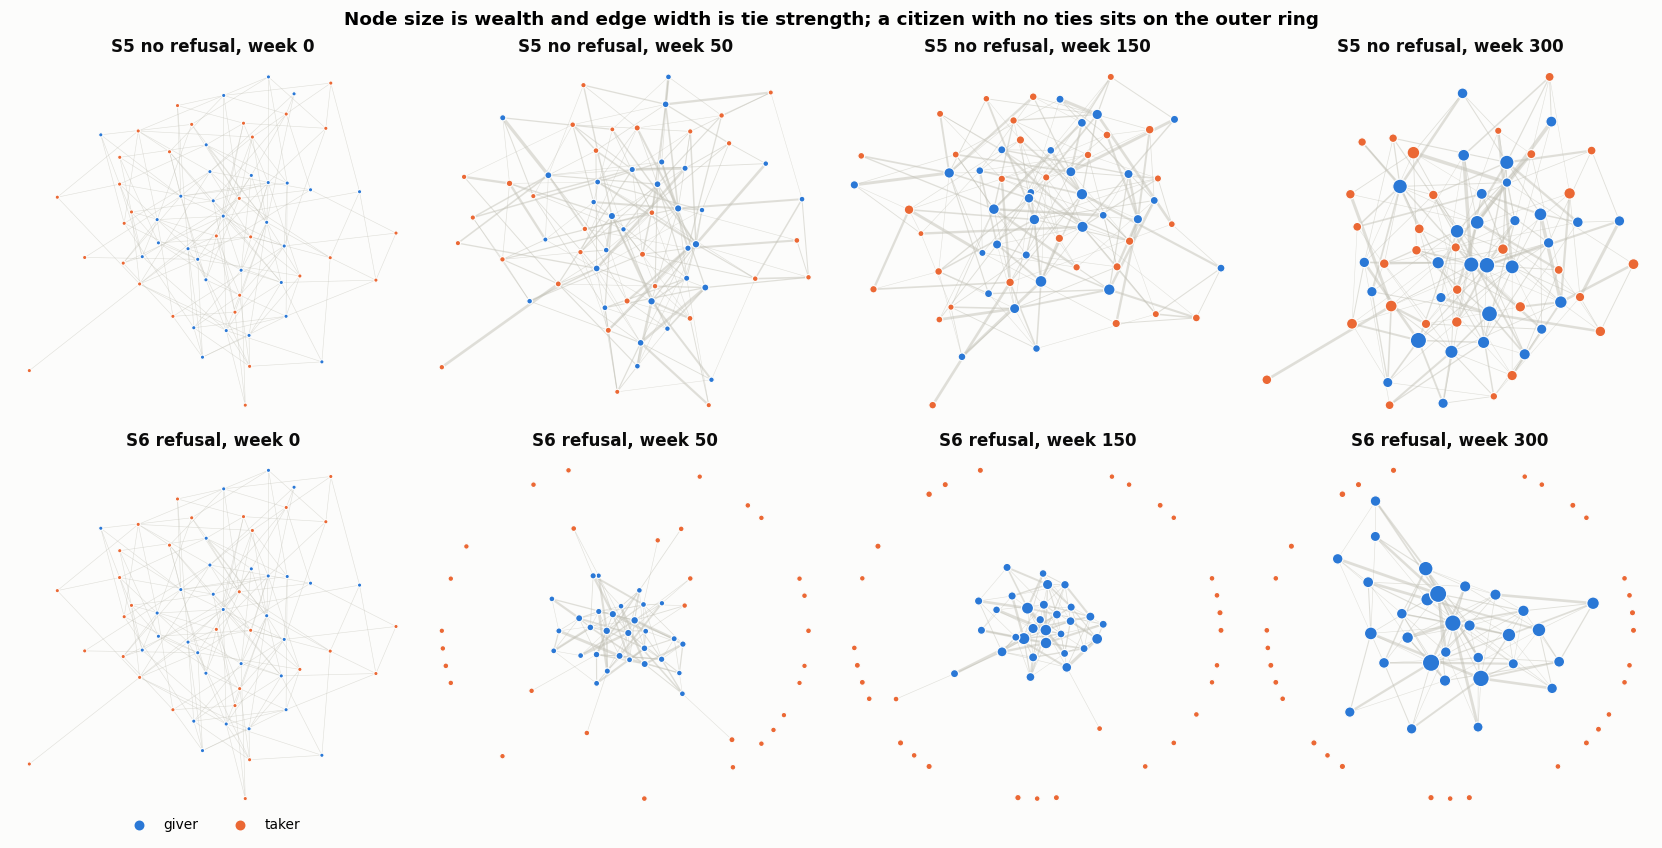

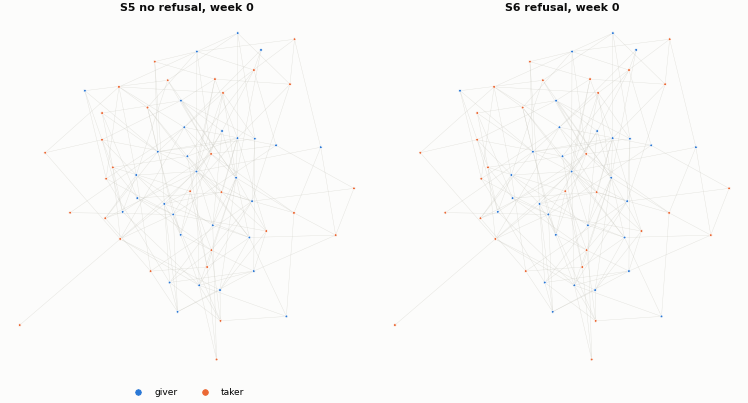

In [22]:
from IPython.display import Image
from utilities.network_draw import animate, class_legend, draw_snapshot, drifting_layouts

# One 60-citizen city at f = 0.5, the same seed and starting network with and without refusal,
# photographed every 10 weeks for 300 weeks.
FILM = {"population.n_agents": 60, "run.n_rounds": 300, "population.giver_fraction": 0.5,
        "metrics.snapshot_every": 10}
films = {label: Simulation(stage(base, **FILM), root_seed=R.DEFAULT_SEED, repeat=0,
                           instruments=("snapshots",)).run().outputs["snapshots"]
         for label, base in [("S5 no refusal", "M4"), ("S6 refusal", "M5")]}

shown = [0, 5, 15, 30]
wealth_scale = (0.0, max(f["wealth"].max() for frames in films.values() for f in frames))
weight_scale = max(f["weight"].max() for frames in films.values() for f in frames)
fig, axes = plt.subplots(2, 4, figsize=(15, 7.6))
for row, (label, frames) in zip(axes, films.items()):
    positions = drifting_layouts(frames, seed=3)
    for ax, k in zip(row, shown):
        draw_snapshot(ax, frames[k], positions[k], title=f"{label}, week {frames[k]['round']}",
                      wealth_scale=wealth_scale, weight_scale=weight_scale, by_class=True)
class_legend(axes[1][0])
fig.suptitle("Node size is wealth and edge width is tie strength; a citizen with no ties sits on the "
             "outer ring", fontweight="bold")
P.save(fig, "city_refusal_frames")
plt.show()

(ROOT / "figures").mkdir(exist_ok=True)
Image(filename=str(animate(films, ROOT / "figures" / "city_refusal.gif", fps=2)))

**Key findings:** Without refusal, the two classes stay mixed throughout, and takers stay
connected to the givers they meet. With refusal, takers move to the outer ring one at a time from
the first weeks: by week 50 many have no ties, and by week 150 nearly all. The givers form a dense
group with strong ties. The takers on the ring do not form a group of their own, because they also
defect on each other.

This is one small city, so it illustrates the results above but is not evidence on its own.

**Model compared to expectations based on reality:** the lack of a group of takers comes from how
our takers are built. AllD and Random defect on everyone, including other takers. Real people who
exploit others often cooperate with each other, so a real city could develop a separate group of
takers, which this model cannot produce.

## Do the Results Depend on Our Settings?

Every result above uses one value for each setting in *Parameter Reference*. Here we change each
main setting on its own, keep everything else as before, and repeat the tests of *Hypothesis Check*
on S5 and S6. Each setting is halved and doubled where the model allows it. The temptation payoff
`T` must stay above `R = 3` and below `2R - S = 6`, the reach is a whole number of steps, and a
random network with a mean degree of 3 is rarely connected, so those use the nearest values that
work. The rating rule is replaced by the two other rules the model has.

| Setting | Usual value | Lower | Higher |
|---|---|---|---|
| Temptation payoff `T` | 5 | 4 | 5.5 |
| Cap on meetings received `c_max` | 4 | 2 | 8 |
| Reach `d_max` | 3 steps | 2 | 4 |
| Pull of habit `beta` | 1 | 0.5 | 2 |
| Pull of status `gamma` | 1 | 0.5 | 2 |
| Tie decay `alpha` | 0.05 | 0.025 | 0.1 |
| Offset `eps` | 0.1 | 0.05 | 0.2 |
| Mean degree `k` | 6 | 4 | 12 |
| City size `N` | 100 | 50 | 200 |
| Rating rule | cooperation x tie strength | cooperation plus tie strength (`weighted_sum`) | payoff given to partners x tie strength (`payoff_delivered`) |

Only S5 and S6 are rerun: the hypotheses are tested on S5, and S6 carries the results on refusal.
Each changed setting is run at the same six giver fractions with the same 5 seeds as the main
experiment: 20 settings x 2 scenarios x 6 fractions x 5 seeds = 1,200 cities, about eleven minutes
with 8 workers. The usual settings are the main experiment's own cities.

In [23]:
# Each setting changed on its own; everything else, including the seeds, as in the main experiment.
VARIANTS = {
    "temptation T = 4":     {"game.payoff": (4.0, 3.0, 1.0, 0.0)},
    "temptation T = 5.5":   {"game.payoff": (5.5, 3.0, 1.0, 0.0)},
    "meeting cap 2":        {"encounter.max_received": 2},
    "meeting cap 8":        {"encounter.max_received": 8},
    "reach 2 steps":        {"encounter.d_max": 2},
    "reach 4 steps":        {"encounter.d_max": 4},
    "habit pull 0.5":       {"encounter.weight_exponent": 0.5},
    "habit pull 2":         {"encounter.weight_exponent": 2.0},
    "status pull 0.5":      {"encounter.popularity_exponent": 0.5},
    "status pull 2":        {"encounter.popularity_exponent": 2.0},
    "tie decay 0.025":      {"ties.decay_rate": 0.025},
    "tie decay 0.1":        {"ties.decay_rate": 0.1},
    "offset 0.05":          {"encounter.eps": 0.05},
    "offset 0.2":           {"encounter.eps": 0.2},
    "mean degree 4":        {"topology.mean_degree": 4},
    "mean degree 12":       {"topology.mean_degree": 12},
    "50 citizens":          {"population.n_agents": 50},
    "200 citizens":         {"population.n_agents": 200},
    "rating: sum":          {"popularity.rule": "weighted_sum"},
    "rating: payoff given": {"popularity.rule": "payoff_delivered"},
}
PAIR = ["S5 full city", "S6 refusal"]
USUAL = "usual settings"
SETTING_ORDER = [USUAL, *VARIANTS]

sens = R.sweep({f"{name}|{scenario}": (SCENARIOS[scenario][0], change)
                for name, change in VARIANTS.items() for scenario in PAIR},
               FRACTIONS, n_seeds=N_SEEDS, workers=WORKERS, **SETTINGS)
sens[["setting", "scenario"]] = sens["scenario"].str.split("|", expand=True)
sens = pd.concat([runs[runs["scenario"].isin(PAIR)].assign(setting=USUAL), sens], ignore_index=True)
sens["n_agents"] = [VARIANTS.get(s, {}).get("population.n_agents", SETTINGS["population.n_agents"])
                    for s in sens["setting"]]


def verdicts(key):
    """The decision rules of *Hypothesis Check*, with the same random streams, on one setting."""
    setting, scenario = key
    cities = sens[(sens["setting"] == setting) & (sens["scenario"] == scenario)]
    cities = cities.rename(columns={"giver_fraction": "population.giver_fraction"})
    h1 = S.h1_threshold(cities, rng=np.random.default_rng(1))
    h4 = S.h4_equal_poverty(cities, rng=np.random.default_rng(4))
    return {"setting": setting, "scenario": scenario, "H1": h1["verdict"],
            "H2": S.h2_decoupling(cities, rng=np.random.default_rng(2))["verdict"],
            "H3": S.h3_segregation(cities, fractions=FRACTIONS[1:-1], rng=np.random.default_rng(3))["verdict"],
            "H4": h4["verdict"], "bic_difference": h1["delta_bic"], "bend_at": h1["break"],
            "slope_below": h1["slope_below"], "slope_above": h1["slope_above"],
            "median_gap": h4["median_gap"][0], "gini_gap": h4["gini_gap"][0],
            "median_vs_gini_low": h4["eta_sq_diff"][1]}


verdict = pd.DataFrame(R.parallel_map(verdicts, [(s, sc) for s in SETTING_ORDER for sc in PAIR], WORKERS))
# H3 is left out for S6: class assortativity cannot be calculated once takers hold no ties.
TESTS = {"S5 full city": ["H1", "H2", "H3", "H4"], "S6 refusal": ["H1", "H2", "H4"]}
usual = verdict[verdict["setting"] == USUAL].set_index("scenario")
changed = verdict[verdict["setting"] != USUAL]
for scenario, tests in TESTS.items():
    for h in tests:
        rows = changed[changed["scenario"] == scenario]
        differ = rows[rows[h] != usual.loc[scenario, h]]
        note = "; ".join(f"{s}: {v}" for s, v in zip(differ["setting"], differ[h]))
        print(f"{scenario.split()[0]} {h}: {usual.loc[scenario, h]} with the usual settings, the same in "
              f"{len(rows) - len(differ)} of {len(rows)} changed settings" + (f" (differs for {note})" if note else ""))
display(verdict.pivot(index="setting", columns="scenario", values=["H1", "H2", "H3", "H4"]).loc[SETTING_ORDER]
        .drop(columns=[("H3", "S6 refusal")]))

# The numbers behind H1 and H4 on S5, and the Gini gap on S6. The gaps are taker-dominated cities
# (f <= 0.3) minus giver-dominated ones (f >= 0.7). median_vs_gini_low is the lower end of the 95%
# interval for how much more of the variation between cities the giver share explains in median wealth
# than in the Gini; H4 is supported only if it is above zero.
by = {sc: verdict[verdict["scenario"] == sc].set_index("setting") for sc in PAIR}
details = by["S5 full city"][["bic_difference", "bend_at", "slope_below", "slope_above", "median_gap",
                              "gini_gap", "median_vs_gini_low"]].assign(gini_gap_S6=by["S6 refusal"]["gini_gap"])
details.loc[SETTING_ORDER].round(3)

S5 H1: supported with the usual settings, the same in 15 of 20 changed settings (differs for temptation T = 5.5: inconclusive; meeting cap 8: inconclusive; status pull 2: inconclusive; tie decay 0.1: inconclusive; offset 0.2: inconclusive)
S5 H2: inconclusive with the usual settings, the same in 18 of 20 changed settings (differs for habit pull 2: refuted; status pull 2: supported)
S5 H3: inconclusive with the usual settings, the same in 19 of 20 changed settings (differs for tie decay 0.1: supported)
S5 H4: supported with the usual settings, the same in 11 of 20 changed settings (differs for temptation T = 5.5: inconclusive; meeting cap 2: refuted; meeting cap 8: inconclusive; reach 2 steps: inconclusive; reach 4 steps: inconclusive; habit pull 2: refuted; status pull 0.5: inconclusive; status pull 2: inconclusive; rating: sum: refuted)
S6 H1: inconclusive with the usual settings, the same in 20 of 20 changed settings
S6 H2: inconclusive with the usual settings, the same in 20 of 20 c

H1                          H2                \
scenario              S5 full city    S6 refusal  S5 full city    S6 refusal   
setting                                                                        
usual settings           supported  inconclusive  inconclusive  inconclusive   
temptation T = 4         supported  inconclusive  inconclusive  inconclusive   
temptation T = 5.5    inconclusive  inconclusive  inconclusive  inconclusive   
meeting cap 2            supported  inconclusive  inconclusive  inconclusive   
meeting cap 8         inconclusive  inconclusive  inconclusive  inconclusive   
reach 2 steps            supported  inconclusive  inconclusive  inconclusive   
reach 4 steps            supported  inconclusive  inconclusive  inconclusive   
habit pull 0.5           supported  inconclusive  inconclusive  inconclusive   
habit pull 2             supported  inconclusive       refuted  inconclusive   
status pull 0.5          supported  inconclusive  inconclusive  inconclusive   
status pull 2         inconclusive  inconclusive     supported  inconclusive   
tie decay 0.025          supported  inconclusive  inconclusive  inconclusive   
tie decay 0.1         inconclusive  inconclusive  inconclusive  inconclusive   
offset 0.05              supported  inconclusive  inconclusive  inconclusive   
offset 0.2            inconclusive  inconclusive  inconclusive  inconclusive   
mean degree 4            supported  inconclusive  inconclusive  inconclusive   
mean degree 12           supported  inconclusive  inconclusive  inconclusive   
50 citizens              supported  inconclusive  inconclusive  inconclusive   
200 citizens             supported  inconclusive  inconclusive  inconclusive   
rating: sum              supported  inconclusive  inconclusive  inconclusive   
rating: payoff given     supported  inconclusive  inconclusive  inconclusive   

                                H3            H4                
scenario              S5 full city  S5 full city    S6 refusal  
setting                                                         
usual settings        inconclusive     supported       refuted  
temptation T = 4      inconclusive     supported       refuted  
temptation T = 5.5    inconclusive  inconclusive       refuted  
meeting cap 2         inconclusive       refuted       refuted  
meeting cap 8         inconclusive  inconclusive  inconclusive  
reach 2 steps         inconclusive  inconclusive       refuted  
reach 4 steps         inconclusive  inconclusive       refuted  
habit pull 0.5        inconclusive     supported       refuted  
habit pull 2          inconclusive       refuted       refuted  
status pull 0.5       inconclusive  inconclusive       refuted  
status pull 2         inconclusive  inconclusive  inconclusive  
tie decay 0.025       inconclusive     supported       refuted  
tie decay 0.1            supported     supported       refuted  
offset 0.05           inconclusive     supported       refuted  
offset 0.2            inconclusive     supported       refuted  
mean degree 4         inconclusive     supported       refuted  
mean degree 12        inconclusive     supported       refuted  
50 citizens           inconclusive     supported       refuted  
200 citizens          inconclusive     supported  inconclusive  
rating: sum           inconclusive       refuted       refuted  
rating: payoff given  inconclusive     supported       refuted

,bic_difference,bend_at,slope_below,slope_above,median_gap,gini_gap,median_vs_gini_low,gini_gap_S6
setting,,,,,,,,
usual settings,17.792,0.29,868.101,1169.296,-572.700,-0.060,0.001,0.049
temptation T = 4,47.633,0.28,964.235,1457.618,-803.250,-0.054,0.007,0.057
temptation T = 5.5,5.180,0.31,824.301,1026.122,-457.575,-0.061,-0.013,0.045
meeting cap 2,40.417,0.30,716.145,1293.905,-998.950,0.010,0.010,0.155
meeting cap 8,2.009,0.28,913.031,1156.995,-456.150,-0.079,-0.029,0.001
reach 2 steps,16.525,0.24,802.026,1166.066,-536.950,-0.065,-0.014,0.051
reach 4 steps,13.338,0.29,848.746,1185.167,-556.250,-0.061,-0.004,0.050
habit pull 0.5,42.072,0.33,875.334,1257.536,-820.850,-0.038,0.003,0.099
habit pull 2,32.333,0.50,840.094,1578.469,-849.700,0.081,-0.010,0.075


**Purpose and layout:** To see which results keep their direction when a setting changes. The
output of the cell above lists, for each hypothesis, how many of the 20 changed settings give the
same verdict as the usual settings. Its first table gives every verdict. Its second gives the numbers
behind H1 and H4 on S5 (the BIC difference, where the bend is, the slopes below and above it, and the
gaps in median wealth and Gini between taker-dominated and giver-dominated cities) and the Gini gap
on S6. The figure below shows four
results the conclusions rest on, one row per setting, with the usual settings at the top in black
and a dashed line at their value. Each dot is the mean of 5 seeds, with one standard error where it
can be calculated seed by seed. From the left: in S5, the Gini of a city with only givers divided by
the highest Gini of a mixed city (`f` = 0.2 to 0.8); in S6, the share of takers with no ties,
averaged over `f` = 0.2 to 0.8; and the change from S5 to S6 at `f = 0.2`, paired by seed, in a
giver's wealth and in wealth per person. All values are at week 500, the week the hypothesis tests
use.

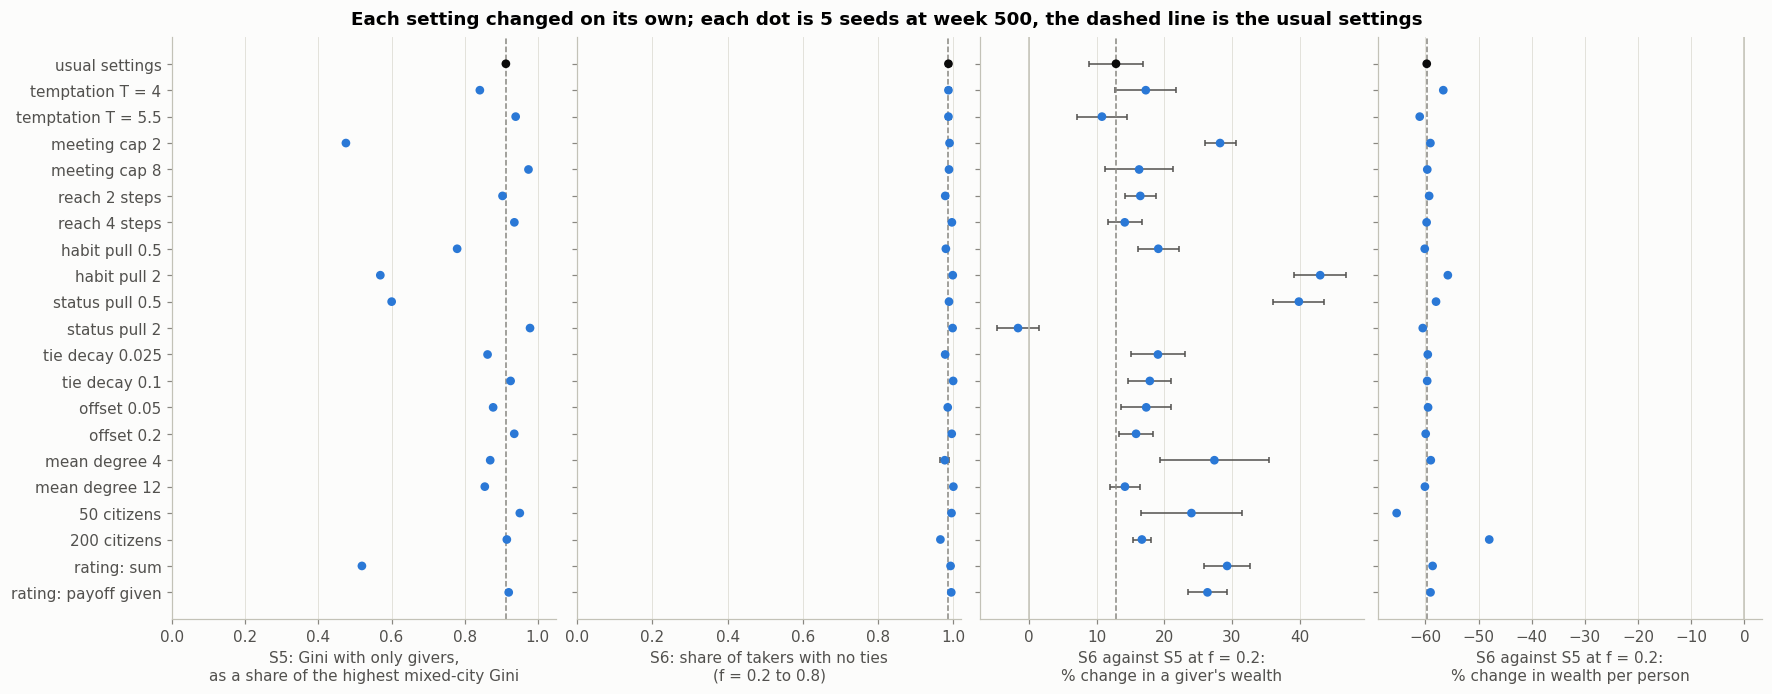

Gini with only givers / highest mixed-city Gini (S5): 0.48 to 0.98
takers with no ties (S6): 0.97 to 1.00
giver wealth, S6 against S5 at f = 0.2: -2% to +43%
wealth per person, S6 against S5 at f = 0.2: -65% to -48%
wealth rises at every step of the giver share: S5 in 21 of 21 settings, S6 in 21 of 21


,gini_givers_only,gini_highest_mixed,all_givers,cut_off,cut_off_se,giver_change,giver_change_se,city_change,city_change_se,wealth_rises_S5,wealth_rises_S6
setting,,,,,,,,,,,
usual settings,0.210,0.230,0.913,0.987,0.006,12.851,3.974,-59.757,0.249,True,True
temptation T = 4,0.210,0.250,0.842,0.987,0.006,17.259,4.520,-56.646,0.277,True,True
temptation T = 5.5,0.210,0.224,0.940,0.987,0.006,10.774,3.733,-61.079,0.249,True,True
meeting cap 2,0.080,0.169,0.475,0.990,0.005,28.248,2.288,-59.068,0.183,True,True
meeting cap 8,0.265,0.272,0.975,0.988,0.004,16.273,5.034,-59.657,0.106,True,True
reach 2 steps,0.215,0.238,0.904,0.978,0.006,16.448,2.324,-59.302,0.183,True,True
reach 4 steps,0.214,0.228,0.936,0.996,0.003,14.147,2.527,-59.782,0.158,True,True
habit pull 0.5,0.152,0.195,0.779,0.980,0.006,19.108,3.038,-60.134,0.092,True,True
habit pull 2,0.179,0.315,0.569,0.998,0.002,43.056,3.848,-55.790,0.397,True,True


In [24]:
# Four results the conclusions rest on, per setting, at week 500.
s5 = sens[sens["scenario"] == "S5 full city"]
gini = s5.groupby(["setting", "giver_fraction"])["gini"].mean().unstack()
mixed = [f for f in FRACTIONS if 0 < f < 1]

s6 = sens[(sens["scenario"] == "S6 refusal") & sens["giver_fraction"].between(0.15, 0.85)].copy()
s6["cut_off"] = s6["isolated_taker"] / (s6["n_agents"] - np.floor(s6["giver_fraction"] * s6["n_agents"] + 0.5))
cut = s6.groupby(["setting", "repeat"])["cut_off"].mean().groupby("setting").agg(["mean", "sem"])

# Refusal's effect where takers are common, paired by seed: the same city with and without refusal.
low = sens[np.isclose(sens["giver_fraction"], 0.2)].pivot_table(index=["setting", "repeat"], columns="scenario",
                                                                values=["wealth_giver", "mean_wealth"])
change = {m: ((low[(m, "S6 refusal")] / low[(m, "S5 full city")] - 1) * 100).groupby("setting").agg(["mean", "sem"])
          for m in ["wealth_giver", "mean_wealth"]}
# Does wealth per person rise at every step of the giver share?
wealth = sens.groupby(["setting", "scenario", "giver_fraction"])["mean_wealth"].mean().unstack()
rises = (wealth.diff(axis=1).iloc[:, 1:] > 0).all(axis=1).unstack("scenario")
effects = pd.DataFrame({
    "gini_givers_only": gini[1.0], "gini_highest_mixed": gini[mixed].max(axis=1),
    "all_givers": gini[1.0] / gini[mixed].max(axis=1),
    "cut_off": cut["mean"], "cut_off_se": cut["sem"],
    "giver_change": change["wealth_giver"]["mean"], "giver_change_se": change["wealth_giver"]["sem"],
    "city_change": change["mean_wealth"]["mean"], "city_change_se": change["mean_wealth"]["sem"],
    "wealth_rises_S5": rises["S5 full city"], "wealth_rises_S6": rises["S6 refusal"],
}).loc[SETTING_ORDER]

fig, axes = plt.subplots(1, 4, figsize=(16, 6.2), sharey=True)
y = np.arange(len(effects))
panels = [("all_givers", None, "S5: Gini with only givers,\nas a share of the highest mixed-city Gini"),
          ("cut_off", "cut_off_se", "S6: share of takers with no ties\n(f = 0.2 to 0.8)"),
          ("giver_change", "giver_change_se", "S6 against S5 at f = 0.2:\n% change in a giver's wealth"),
          ("city_change", "city_change_se", "S6 against S5 at f = 0.2:\n% change in wealth per person")]
for ax, (column, se, label) in zip(axes, panels):
    colours = [P.INK if name == USUAL else P.SERIES[0] for name in effects.index]
    ax.errorbar(effects[column], y, xerr=None if se is None else effects[se], fmt="none", ecolor=P.INK_2,
                capsize=2, elinewidth=1)
    ax.scatter(effects[column], y, c=colours, s=22, zorder=3)
    ax.axvline(effects.loc[USUAL, column], color=P.MUTED, linewidth=1, linestyle="--")
    if column.endswith("change"):
        ax.axvline(0, color=P.AXIS, linewidth=1)
    ax.set_xlabel(label)
    ax.grid(axis="y", visible=False)
# Both shares start at zero, so a small spread near the top is not drawn as a large one.
axes[0].set_xlim(0, 1.05)
axes[1].set_xlim(0, 1.02)
axes[0].set_yticks(y, effects.index)
axes[0].invert_yaxis()
fig.suptitle(f"Each setting changed on its own; each dot is {N_SEEDS} seeds at week 500, the dashed line is the "
             "usual settings", fontweight="bold")
P.save(fig, "sensitivity")
plt.show()

print(f"Gini with only givers / highest mixed-city Gini (S5): {effects['all_givers'].min():.2f} to {effects['all_givers'].max():.2f}")
print(f"takers with no ties (S6): {effects['cut_off'].min():.2f} to {effects['cut_off'].max():.2f}")
print(f"giver wealth, S6 against S5 at f = 0.2: {effects['giver_change'].min():+.0f}% to {effects['giver_change'].max():+.0f}%")
print(f"wealth per person, S6 against S5 at f = 0.2: {effects['city_change'].min():+.0f}% to {effects['city_change'].max():+.0f}%")
print(f"wealth rises at every step of the giver share: S5 in {effects['wealth_rises_S5'].sum()} of {len(effects)} "
      f"settings, S6 in {effects['wealth_rises_S6'].sum()} of {len(effects)}")
effects.round(3)

**Key findings:**

- **The results on refusal hold in every setting:** 97% to 100% of takers have no ties at week 500,
  and at 20% givers the city is 48% to 65% poorer with refusal than without. Wealth per person rises
  with the share of givers in S5 and S6 in all 20 settings. On S6, the verdicts for H1 and H2 never
  change, and H4 is refuted in 17 of 20 settings. In the other three it is inconclusive: with 200
  citizens or a meeting cap of 8, taker-dominated cities are about as unequal as giver-dominated
  ones (Gini 0.001 higher), and with a status pull of 2 they are slightly more equal (0.032 lower).
- **Refusal protects givers in 19 of 20 settings:** at 20% givers, a giver ends 11% to 43% richer
  with refusal. The exception is a status pull of 2, where a giver's wealth does not change (-2%,
  standard error 3). We have not looked into why.
- **The bend in S5 (H1) always goes the same way, but is not always strong enough to pass the
  test:** in every setting, wealth rises faster above the bend than below it. H1 is supported in 15
  of 20 settings. In the other five (meeting cap 8, offset 0.2, status pull 2, temptation 5.5, tie
  decay 0.1), the bent line does not fit enough better than a straight one (BIC difference 2 to 8,
  against the 10 the test requires). The giver share at the bend moves between 0.07 and 0.50, so it
  is a property of the settings, not a fixed threshold.
- **A city where nobody cheats is always unequal, but how unequal depends on reputation:** with only
  givers, the S5 Gini is between 0.080 and 0.313 in every setting, against 0.013 in S1. In 16
  settings it is at least three quarters of the most unequal mixed city's Gini; in the other four it
  is about half (0.48 to 0.60). Three of those four limit how much a well-rated citizen can be met: a
  cap of 2 meetings received, a status pull of 0.5, and a rating that adds cooperation and tie
  strength instead of multiplying them, which narrows the range of ratings. This matches
  *Inequality When Nobody Is Cheated*, where removing reputation from partner choice removed most of
  the inequality. The fourth, a habit pull of 2, makes mixed cities more unequal (0.315) rather than
  the city of givers more equal.
- **H4 on S5 is the least robust verdict:** taker-dominated cities are poorer in all 20 settings, and
  more equal in 16. H4 is supported in 11 settings. It is inconclusive in six: in five of them
  (meeting cap 8, reach 2 and 4, status pull 2, temptation 5.5) the giver share does not explain
  more of the differences in median wealth than of the differences in the Gini, which the test also
  requires; with a status pull of 0.5, taker-dominated cities are about as unequal as giver-dominated
  ones (Gini 0.001 higher). It is refuted in three
  (habit pull 2, meeting cap 2, rating by sum), where taker-dominated cities are more unequal (Gini
  0.010 to 0.081 higher). All three are among the four settings, in the previous point, in which a city
  of givers is about half as unequal as the most unequal mixed city.
- **H2 and H3 on S5 stay inconclusive in 18 and 19 of 20 settings:** H2 becomes supported with a
  status pull of 2 and refuted with a habit pull of 2. H3 becomes supported with a tie decay of 0.1.

## Emergent Behaviour

Downey defines an emergent property as "a characteristic of a system that results from the
interaction of its components, not from their properties", and adds that emergent properties are
hard to predict even when all the rules are known [3, pp. 155-156]. Using that definition, the results above fall
into two groups.

**Results that follow directly from the rules:**

- **More givers make a city richer:** this follows from the payoffs. A game between two givers
  creates 6 units of wealth, a game between a giver and a taker creates 5, and a game between two
  takers creates 2 (*Insight 1*).
- **Cooperation does not evolve:** strategies never change, so the share of givers is set at the
  start. The model cannot show cooperation spreading through a city; it shows what a given mix
  produces.
- **Joss under refusal:** its advantage over AllD and Random matches what its defection rate
  predicts in direction and roughly in size, though it is smaller than predicted (*A Taker That
  Cooperates Most of the Time*).

**Results that come from citizens interacting:**

| Pattern | Measured in | Why no rule produces it directly | How it arises | Concept |
|---|---|---|---|---|
| A city where nobody cheats is unequal (Gini 0.210), and who is ahead is settled early (rank correlation 0.80 between week 25 and week 500) | *Inequality When Nobody Is Cheated* | Every citizen plays Tit-for-Tat and no rule favours anyone | Being met often raises a citizen's rating, which gets it met more | Positive feedback and path dependence |
| Cooperation in the city rises (+0.109 with partner choice, +0.278 with refusal) although no citizen changes strategy | *What Each Step of the Model Changes* | No citizen becomes more cooperative | Givers end up playing each other more often | Self-organisation |
| Without refusal, ties link givers and takers slightly more often than chance (S4 and S5) | *Who Ends Up Connected to Whom* | No rule mentions class | Every citizen, takers included, seeks well-rated partners, and those are givers | A collective outcome opposite to H3's expectation |
| With refusal, takers are cut off as a class (97% to 100% with no ties at week 500), and the ties that remain are almost all between givers | *Letting Citizens Refuse (S6)* | Refusal is between two citizens and never mentions class | Every taker defects on each partner sooner or later, so each of its pairs closes in turn | Segregation from local rules, as in Schelling's model [3, p. 155] |
| Refusals longer than 52 weeks start to cut takers off and cost the city wealth; shorter ones only change who is poor | *How Long a Refusal Lasts* | The refusal length changes smoothly | Takers run out of citizens within reach who will still meet them | Threshold |

Downey calls the unequal wealth in Sugarscape "a weak example" of emergence, because it could be
predicted from the agents' different vision, metabolism and lifespan [3, p. 156]. In our city where everyone
plays Tit-for-Tat, citizens differ only in their starting ties, and the number of starting ties
predicts the final ranking only partly (correlation 0.66). Most of the inequality comes from the
feedback between being met and being rated: without reputation in partner choice, the Gini is 0.052
instead of 0.210.

Downey also notes that the status of emergent properties is debated, and that to some people
"emergence" is another name for ignorance [3, p. 156]. For every pattern in the table we can name the mechanism
in the model that produces it. We call these patterns emergent in the sense of the definition: they
belong to the city, not to any citizen's rule.

## Conclusions

Our research question was: in simulated cities that differ in their mix of givers and takers, what
patterns emerge in prosperity, in how that prosperity is shared, and in who ends up connected to
whom? We answer it for cities without refusal (S1 to S5) and with permanent refusal (S6), using 5
seeds per setting.

### Prosperity

More givers always make a city richer, in every scenario. Without refusal, wealth rises faster once
givers are common, because givers create the most wealth when they meet each other: in S5 a bent
line fits better than a straight one (BIC difference 18), with the bend at a giver share of 0.29,
so **H1 is supported** with our settings. When we change the settings one at a time, wealth always
rises faster above the bend than below it, but in 5 of 20 changed settings the bend is too weak to
pass the test, and the giver share where it happens moves between 0.07 and 0.50. Below the bend no
city collapses into defection, because citizens never change strategy. With permanent refusal there
is no such bend. Each extra 20% of givers adds a
little less than the one before, so H1 is not supported on S6. Refusal also makes cities with many
takers much poorer (at 20% givers, 842 per person against 2,093), because a taker that nobody meets
creates no wealth.

### How prosperity is shared

Without refusal, most inequality comes from differences in how often citizens are met, not from
cheating. A city where nobody is ever cheated has a Gini of 0.210, close to a mixed city's 0.226,
and removing reputation from partner choice brings it down to 0.05. In S5, inequality rises as the
share of givers goes from 0 to 40%, then stays level, and only falls when every citizen is a giver.
So prosperity and equality do separate, but in the middle of the range rather than in the richest
cities, and the cause we find is unequal attention rather than clustering: **H2 is inconclusive**.

Without refusal, taker-dominated cities are poorer and more equal (median wealth 573 lower, Gini
0.060 lower), so **H4 is supported** with our settings. This is the verdict that depends most on the
settings. Taker-dominated cities are poorer in all 20 changed settings and more equal in 16, but H4
passes its full test in only 11 and is refuted in 3. Those 3 (a meeting cap of 2, a habit pull of 2,
and a rating that adds cooperation and tie strength) are settings in which a city of givers is about
half as unequal as the most unequal mixed city. So whether poor cities are also equal depends on how
strongly reputation decides who meets whom. With permanent refusal they are poorer and more unequal (median
wealth 2,091 lower, Gini 0.049 higher), so H4 is refuted on S6: the few givers stay rich while most
takers are cut off.

A short refusal of one week barely changes the Gini, but the share of inequality between givers and
takers rises from 0.19 to 0.84 (20% givers). The Gini alone does not show this change, so we report
who holds the inequality as well as how much there is.

### Who ends up connected to whom

Without refusal, takers end with fewer partners and weaker ties than givers, but they are not
pushed to the edge: ties link givers and takers slightly more often than chance, because everyone
chooses well-rated partners and givers cannot decline. One part of H3 holds and the other does not,
so **H3 is inconclusive**. With refusal, almost every taker ends with no ties at all. Segregation
does happen, but as exclusion of takers, not as two separate groups.

| Hypothesis | Without refusal (S5) | With permanent refusal (S6) |
|---|---|---|
| H1 Prosperity threshold | Supported (same in 15 of 20 changed settings) | Not supported: no upward bend (20 of 20) |
| H2 Prosperity and equality decouple | Inconclusive: inequality levels off in the middle, not at the top (18 of 20) | Inconclusive (20 of 20) |
| H3 Emergent segregation | Inconclusive: takers have fewer ties, but the classes do not separate (19 of 20) | Not testable: takers end with no ties |
| H4 The poverty trap is equal | Supported (11 of 20; refuted in 3) | Refuted (17 of 20) |

The counts in brackets are how many of the 20 changed settings in *Do the Results Depend on Our
Settings?* give the same verdict as the usual settings.

**Checks and sensitivity to the settings:** the model passes all 25 checks in *Checks*. When each of
ten settings is changed on its own, wealth always rises with the share of givers, a city where nobody cheats is always unequal, and refusal always cuts
takers off and makes cities with many takers poorer; but H1 on S5 passes its test in 15 of the 20
changed settings and H4 on S5 in only 11, so those two verdicts depend on our settings (*Do the
Results Depend on Our Settings?*).

**Emergent behaviour:** inequality in a city where nobody cheats, the exclusion of takers as a class
under refusal, and the rise in cooperation without any citizen changing strategy are not written into
any rule; they come from citizens interacting (*Emergent Behaviour*). The rise in prosperity with
more givers is not emergent, because it follows from the payoffs, and cooperation does not evolve,
because strategies are fixed.

### What these results can and cannot tell us

Some results come from how the model is built and should not be read as statements about real
cities: the giver share at which wealth bends upwards, the refusal length at which the city starts
to lose wealth, the permanence of exclusion (our takers can never change), and the absence of a
group of takers (our takers cheat each other too). Other results match evidence from real people:
success depends partly on early attention [16], people cut ties with those who cheat them
[12], and excluding selfish members reduces cheating [18]. The difference between how
much inequality there is and who holds it is a property of the measures, so it applies to any
population.

## Limitations and Future Work

### Limitations

- **Five seeds per setting:** enough for the large effects of partner choice and refusal, but not
  for small ones. The effect of clustering on cooperation, and whether refusal helps a giver
  surrounded by takers, are within their standard errors.
- **One city size in most results:** most results are for cities of 100. The sensitivity test
  repeats the hypothesis tests at 50 and 200 citizens, where every verdict is the same except H4 on
  S6 at 200 citizens, which becomes inconclusive.
- **Strategies never change:** nobody learns or copies a richer neighbour, so the mix of givers and
  takers is set at the start.
- **Refusal is perfect and personal:** every cheated citizen notices every defection and acts on it
  alone. Nobody hears about a cheat from anyone else, and no defection is a mistake.
- **S6 has not settled by week 500:** takers are still being cut off, so its results describe a city
  that is still changing.
- **Most takers are easy to spot:** AllD never cooperates and Random cooperates half the time. Joss
  shows that a taker that cooperates more escapes most of the effect of refusal, but it is the only
  such taker we tested, and only at one mix.
- **Wealth is never spent:** there is no cost of living, investment or inheritance, and no citizen's
  choices depend on its wealth.
- **Closed cities:** nobody is born, dies, arrives or leaves, and each seed gives one starting
  network.

### Future work

1. **Let strategies spread:** allow citizens to copy more successful neighbours, to test whether
   refusal helps cooperation spread through a city of takers, as walking away does in simulations
   of evolving strategies [17].
2. **Refusal based on reputation:** the model can already refuse anyone rated below a threshold
   (`encounter.refusal = "reputation"`). This could stop a taker like Joss before it cheats each new
   partner, but might also cut off givers who simply have few ties.
3. **Mistakes in refusal:** with a chance that a cooperative move is mistaken for a defection,
   permanent refusal would also cut off some givers.
4. **A cost of living:** a cost per week would mean poor citizens can lose wealth, which is closer
   to real poverty.
5. **Compare with data:** connections between rich and poor, and economic mobility, have been
   measured at large scale [2]; matching the model to such data would allow numerical
   comparisons.

## References

[1] X. Xue, W. R. Reed, and R. C. M. van Aert, "Social capital and economic growth: A meta-analysis," *Journal of Economic Surveys*, vol. 39, no. 4, pp. 1395-1432, Sep. 2025, doi: 10.1111/joes.12660.

[2] R. Chetty et al., "Social capital I: Measurement and associations with economic mobility," *Nature*, vol. 608, no. 7921, pp. 108-121, Aug. 2022, doi: 10.1038/s41586-022-04996-4.

[3] A. B. Downey, *Think Complexity: Complexity Science and Computational Modeling*, 2nd ed. Sebastopol, CA, USA: O'Reilly Media, 2018.

[4] L.-L. Jiang, Y.-M. Li, W.-J. Li, and A. Szolnoki, "Combined effect of incentives and coupling in multigames in two-layer networks," *Journal of Physics: Complexity*, vol. 6, no. 1, Art. no. 015003, Mar. 2025, doi: 10.1088/2632-072X/ada844.

[5] M. Tsvetkova, "The effects of reputation on inequality in network cooperation games," *Philosophical Transactions of the Royal Society B*, vol. 376, no. 1838, Art. no. 20200299, Nov. 2021, doi: 10.1098/rstb.2020.0299.

[6] M. Tsvetkova, C. Wagner, and A. Mao, "The emergence of inequality in social groups: Network structure and institutions affect the distribution of earnings in cooperation games," *PLOS ONE*, vol. 13, no. 7, Art. no. e0200965, Jul. 2018, doi: 10.1371/journal.pone.0200965.

[7] A. Nishi, H. Shirado, D. G. Rand, and N. A. Christakis, "Inequality and visibility of wealth in experimental social networks," *Nature*, vol. 526, no. 7573, pp. 426-429, Oct. 2015, doi: 10.1038/nature15392.

[8] M. A. Nowak and R. M. May, "Evolutionary games and spatial chaos," *Nature*, vol. 359, no. 6398, pp. 826-829, Oct. 1992, doi: 10.1038/359826a0.

[9] D. Melamed, A. Harrell, and B. Simpson, "Cooperation, clustering, and assortative mixing in dynamic networks," *Proceedings of the National Academy of Sciences*, vol. 115, no. 5, pp. 951-956, Jan. 2018, doi: 10.1073/pnas.1715357115.

[10] J. Szüle, D. Kondor, L. Dobos, I. Csabai, and G. Vattay, "Lost in the city: Revisiting Milgram's experiment in the age of social networks," *PLOS ONE*, vol. 9, no. 11, Art. no. e111973, Nov. 2014, doi: 10.1371/journal.pone.0111973.

[11] W. Ahmad, M. A. Porter, and M. Beguerisse-Díaz, "Tie-decay networks in continuous time and eigenvector-based centralities," *IEEE Transactions on Network Science and Engineering*, vol. 8, no. 2, pp. 1759-1771, Apr. 2021, doi: 10.1109/TNSE.2021.3071429.

[12] D. G. Rand, S. Arbesman, and N. A. Christakis, "Dynamic social networks promote cooperation in experiments with humans," *Proceedings of the National Academy of Sciences*, vol. 108, no. 48, pp. 19193-19198, Nov. 2011, doi: 10.1073/pnas.1108243108.

[13] V. M. R. Muggeo, "Estimating regression models with unknown break-points," *Statistics in Medicine*, vol. 22, no. 19, pp. 3055-3071, Oct. 2003, doi: 10.1002/sim.1545.

[14] A. E. Raftery, "Bayesian model selection in social research," *Sociological Methodology*, vol. 25, pp. 111-163, 1995, doi: 10.2307/271063.

[15] B. Efron, "Bootstrap methods: Another look at the jackknife," *The Annals of Statistics*, vol. 7, no. 1, pp. 1-26, Jan. 1979, doi: 10.1214/aos/1176344552.

[16] M. J. Salganik, P. S. Dodds, and D. J. Watts, "Experimental study of inequality and unpredictability in an artificial cultural market," *Science*, vol. 311, no. 5762, pp. 854-856, Feb. 2006, doi: 10.1126/science.1121066.

[17] C. A. Aktipis, "Know when to walk away: Contingent movement and the evolution of cooperation," *Journal of Theoretical Biology*, vol. 231, no. 2, pp. 249-260, Nov. 2004, doi: 10.1016/j.jtbi.2004.06.020.

[18] M. Feinberg, R. Willer, and M. Schultz, "Gossip and ostracism promote cooperation in groups," *Psychological Science*, vol. 25, no. 3, pp. 656-664, Mar. 2014, doi: 10.1177/0956797613510184.

[19] A. F. Shorrocks, "The class of additively decomposable inequality measures," *Econometrica*, vol. 48, no. 3, pp. 613-625, Apr. 1980, doi: 10.2307/1913126.

[20] R. Axelrod, "Effective choice in the Prisoner's Dilemma," *Journal of Conflict Resolution*, vol. 24, no. 1, pp. 3-25, Mar. 1980, doi: 10.1177/002200278002400101.